# PA44: heat-event stream processing

Python implementation for Portimão and Covilhã. The cells load hourly ERA5 weather, construct a binary temperature target and temporal predictors, replay incremental classifiers, and display descriptive tables, correlations and model metrics.


## Target and time alignment

For eligible Monday–Friday hours from 08:00 to before 18:00 Europe/Lisbon time, `y_event` is 1 when observed temperature is at least `TEMPERATURE_THRESHOLD_C` (configured as 30 °C), otherwise 0. Weather predictors use observations before the target hour; local forecast hour is known in advance.

The 28/30/32 °C comparison later in the notebook calculates descriptive event counts without changing the trained target.


## Environment and configuration

Use the project Python environment and its requirements. The next cell defines cities, dates, variables, model feature lists, output folders and random seed. `FORCE_DOWNLOAD` refreshes cached responses; `DEVELOPMENT_MODE` limits the replay to a shorter input sequence.


In [103]:
from __future__ import annotations
import json, math, os, platform, sys, time, warnings
from collections import deque
from datetime import datetime
from pathlib import Path
import importlib.metadata as importlib_metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

PA_CODE = 'PA44'
STUDENTS = {'A': ('Diogo Caldeirinha', '20231689'), 'B': ('Arsenii Prorokov', '20230784')}
CITIES = {
    'Portimão': {'latitude': 37.1366, 'longitude': -8.5377},
    'Covilhã': {'latitude': 40.2806, 'longitude': -7.5039},
}
CITY_A, CITY_B = tuple(CITIES)
START_DATE, END_DATE = '2023-01-01', '2025-12-31'
TZ_LOCAL, TZ_API = 'Europe/Lisbon', 'GMT'
ARCHIVE_URL = 'https://archive-api.open-meteo.com/v1/archive'
REANALYSIS_MODEL = 'era5'
# Only these measured weather fields are requested from Open-Meteo.
RAW_VARIABLES = [
    'temperature_2m', 'relative_humidity_2m',
    'precipitation', 'wind_speed_10m'
]
# Calculated locally on each city's uninterrupted hourly history.
INITIAL_MA_FEATURES = [
    'humidity_mean_3h_lag24',  # Humidity MA3 L24: at 10:00, yesterday 08:00–10:00
    'precipitation_mean_24h', # Precip MA 24h: preceding 24 hours, ending at t−1
    'humidity_mean_3h',       # Humidity MA 3h: preceding 3 hours, ending at t−1
]
# The two newly selected predictors are enabled in Representation B.
MODEL_SELECTED_FEATURES = ['humidity_mean_24h', 'local_hour']
MODEL_MA_FEATURES = INITIAL_MA_FEATURES + ['humidity_mean_24h']
MODEL_TIME_FEATURES = ['local_hour']  # Forecast-hour calendar value is known in advance.
TARGET_VARIABLE = 'y_event'   # Heat event: target, never a predictor
# Combined data-column list; model inputs are selected separately by REP_A/REP_B.
VARIABLES = RAW_VARIABLES + MODEL_MA_FEATURES + MODEL_TIME_FEATURES + [
    TARGET_VARIABLE,
    'lag1_temperature_2m',    # Lag temp
    'lag1_relative_humidity_2m',  # Lag humidity
]
TEMPERATURE_THRESHOLD_C = 30.0
SHIFT_WEEKDAYS = (0, 1, 2, 3, 4)  # Monday to Friday
SHIFT_START, SHIFT_END = 8, 18  # [08,18) local-time hours
WARMUP_FRACTION = 0.20
RANDOM_SEED = 42
CHECKPOINT_EVERY = 150
ROLLING_SCORE_WINDOW = 300
ENSEMBLE_SIZE = 5
DEVELOPMENT_MODE = False  # True limits the replay length
SMOKE_MAX_TIMESTAMPS = 2000
MIN_PREDICTOR_COVERAGE = 0.70  # Reject unusable sources; otherwise warm-up-only median imputation
FORCE_DOWNLOAD = False  # Reuse existing cached ERA5 snapshots; set True only when refreshing

# Notebook outputs resolve relative to where the notebook is launched.
BASE = Path.cwd() / 'PA44_outputs'
RAW_DIR, DATA_DIR, FIG_DIR, TABLE_DIR = [BASE / p for p in ('data/raw', 'data/processed', 'figures', 'tables')]
for folder in [RAW_DIR, DATA_DIR, FIG_DIR, TABLE_DIR]: folder.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

def package_version(pkg):
    try: return importlib_metadata.version(pkg)
    except importlib_metadata.PackageNotFoundError: return 'NOT INSTALLED'

meta = {'python': sys.version.split()[0], 'platform': platform.platform(),
        'processor': platform.processor(), 'logical_cpus': os.cpu_count(),
        'packages': {p: package_version(p) for p in ('numpy','pandas','requests','scikit-learn','matplotlib','river')},
        'started_utc': datetime.now().astimezone().isoformat(),
        'development_mode': DEVELOPMENT_MODE, 'random_seed': RANDOM_SEED}
(DATA_DIR / 'environment.json').write_text(json.dumps(meta, indent=2), encoding='utf-8')
print('Data and report outputs:', BASE)
print('Environment:', meta)

Data and report outputs: c:\Users\arpro\Documents\NOVA\DataStream\cleared\PA44_outputs
Environment: {'python': '3.13.14', 'platform': 'Windows-11-10.0.26200-SP0', 'processor': 'Intel64 Family 6 Model 198 Stepping 2, GenuineIntel', 'logical_cpus': 24, 'packages': {'numpy': '2.5.3', 'pandas': '2.3.3', 'requests': '2.34.2', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'river': '0.23.0'}, 'started_utc': '2026-10-16T11:38:51.217537+01:00', 'development_mode': False, 'random_seed': 42}


## Load hourly weather

`cached_open_meteo_year` loads a yearly ERA5 JSON response or retrieves it from Open-Meteo. `hourly_to_frame` parses UTC timestamps and numeric columns. `load_city` combines years and reindexes to the complete hourly calendar. The next cell tabulates missing values, ranges and IQR flags.


In [104]:
def cached_open_meteo_year(city_name, year):
    path = RAW_DIR / f'{city_name.lower().replace("ã", "a").replace("í", "i")}_{year}_{REANALYSIS_MODEL}.json'
    if path.exists() and not FORCE_DOWNLOAD:
        return json.loads(path.read_text(encoding='utf-8'))
    location = CITIES[city_name]
    params = {'latitude': location['latitude'], 'longitude': location['longitude'],
              'start_date': f'{year}-01-01', 'end_date': f'{year}-12-31',
              'hourly': ','.join(RAW_VARIABLES), 'timezone': TZ_API,
              'models': REANALYSIS_MODEL, 'temperature_unit': 'celsius',
              'wind_speed_unit': 'kmh', 'precipitation_unit': 'mm'}
    session = requests.Session()
    retry = Retry(total=4, backoff_factor=1.5, status_forcelist=[429,500,502,503,504])
    session.mount('https://', HTTPAdapter(max_retries=retry))
    print(f'Retrieving {city_name}, {year} from Open-Meteo...')
    try:
        resp = session.get(ARCHIVE_URL, params=params, timeout=(15, 120))
        resp.raise_for_status()
        data = resp.json()
    except requests.RequestException as exc:
        raise RuntimeError(f'API request failed for {city_name} {year}. '
                           f'An internet connection is needed for the first run. {exc}') from exc
    finally:
        session.close()
    if data.get('error'):
        raise RuntimeError(f'Open-Meteo rejected {city_name}, {year}: {data.get("reason")}')
    if ('hourly' not in data or 'time' not in data['hourly'] or
        any(v not in data['hourly'] for v in RAW_VARIABLES)):
        raise ValueError('Missing expected Open-Meteo hourly fields: ' + str(data.keys()))
    path.write_text(json.dumps(data, ensure_ascii=False), encoding='utf-8')
    return data

def hourly_to_frame(payload, city_name):
    hour = payload['hourly']
    count = len(hour['time'])
    if any(len(hour[c]) != count for c in RAW_VARIABLES):
        raise ValueError(f'Hour and feature lengths differ for {city_name}')
    timestamps = pd.to_datetime(hour['time'], errors='raise', utc=True)
    frame = pd.DataFrame({c: pd.to_numeric(pd.Series(hour[c]), errors='coerce').to_numpy()
                          for c in RAW_VARIABLES}, index=pd.DatetimeIndex(timestamps, name='timestamp_utc'))
    if frame.index.has_duplicates: raise ValueError(f'Duplicate UTC timestamps: {city_name}')
    return frame.sort_index()

def load_city(city_name):
    frames = [hourly_to_frame(cached_open_meteo_year(city_name, year), city_name)
              for year in range(2023, 2026)]
    f = pd.concat(frames).sort_index()
    expected = pd.date_range('2023-01-01', '2025-12-31 23:00', freq='h', tz='UTC', name='timestamp_utc')
    if f.index.difference(expected).size: raise ValueError(f'Unexpected timestamp in {city_name}')
    gaps = expected.difference(f.index)
    f = f.reindex(expected)  # gaps remain NaN; do not silently compress time
    f['city'] = city_name
    print(city_name, '| observed rows:', len(f) - len(gaps), '| missing UTC hours:', len(gaps))
    return f

raw = {city: load_city(city) for city in CITIES}
assert set(raw[CITY_A].index) == set(raw[CITY_B].index)

Portimão | observed rows: 26304 | missing UTC hours: 0
Covilhã | observed rows: 26304 | missing UTC hours: 0


In [105]:
def make_qa_table(city_data):
    result = []
    for name, df in city_data.items():
        local = df.index.tz_convert(TZ_LOCAL)
        hours = (local.weekday < 5) & (local.hour >= SHIFT_START) & (local.hour < SHIFT_END)
        for variable in RAW_VARIABLES:
            s = df[variable]
            vals = s.dropna()
            q1, q3 = vals.quantile([0.25, 0.75]) if len(vals) else (np.nan, np.nan)
            iqr = q3 - q1
            fences = ((vals < q1 - 3 * iqr) | (vals > q3 + 3 * iqr)) if pd.notna(iqr) else pd.Series(dtype=bool)
            result.append({'city': name, 'variable': variable, 'n_hours': len(df),
                           'missing_n': int(s.isna().sum()), 'missing_pct': 100*s.isna().mean(),
                           'min': vals.min(), 'median': vals.median(), 'max': vals.max(),
                           'wide_IQR_flags': int(fences.sum())})
        result.append({'city': name, 'variable': '__WORK_HOURS__', 'n_hours': int(hours.sum()),
                       'missing_n': int(df.loc[hours, 'temperature_2m'].isna().sum())})
    return pd.DataFrame(result)

qa = make_qa_table(raw)
qa.to_csv(TABLE_DIR/'data_quality_full.csv', index=False)
display(qa.round(2))
print('Wide-IQR flags are REVIEW indicators, not grounds for automatically deleting genuine heat extremes.')

,city,variable,n_hours,missing_n,missing_pct,min,median,max,wide_IQR_flags
0,Portimão,temperature_2m,26304,0,0.0,1.6,18.0,41.3,0.0
1,Portimão,relative_humidity_2m,26304,0,0.0,11.0,75.0,100.0,0.0
2,Portimão,precipitation,26304,0,0.0,0.0,0.0,9.3,2825.0
3,Portimão,wind_speed_10m,26304,0,0.0,0.0,11.8,51.9,1.0
4,Portimão,__WORK_HOURS__,7830,0,NaN,NaN,NaN,NaN,NaN
5,Covilhã,temperature_2m,26304,0,0.0,-3.6,13.5,39.4,0.0
6,Covilhã,relative_humidity_2m,26304,0,0.0,9.0,76.0,100.0,0.0
7,Covilhã,precipitation,26304,0,0.0,0.0,0.0,11.3,5312.0
8,Covilhã,wind_speed_10m,26304,0,0.0,0.0,7.9,33.5,26.0
9,Covilhã,__WORK_HOURS__,7830,0,NaN,NaN,NaN,NaN,NaN


Wide-IQR flags are REVIEW indicators, not grounds for automatically deleting genuine heat extremes.


### Paired stream configuration

`construct_stream` derives the target, local calendar and past-weather predictors on the full hourly series. Both cities are restricted to shared eligible timestamps with observed targets and previous-hour temperature. Weather inputs are forward-filled for at most three hours; remaining predictor gaps use pooled warm-up medians.

The first `WARMUP_FRACTION` of shared timestamps forms the warm-up. `REP_A` selects four previous-hour measurements; `REP_B` selects thirteen columns. The cell displays the configuration, feature coverage and imputation counts.


In [106]:
# Feature definitions and paired timestamp selection
REP_A = ['lag1_temperature_2m', 'lag1_relative_humidity_2m',
         'lag1_precipitation', 'lag1_wind_speed_10m']
# Keep the previous 11-feature set fixed for the historical comparison sections.
REP_B_PREVIOUS = REP_A + [
    'temp_delta_1h', 'temp_mean_6h', 'temp_max_24h', 'humidity_mean_6h'
] + INITIAL_MA_FEATURES
REP_B = REP_B_PREVIOUS + MODEL_SELECTED_FEATURES
REP_B_EXTRA = REP_B[len(REP_A):]
assert len(REP_A) == 4 and len(REP_B_PREVIOUS) == 11 and len(REP_B) == 13
assert len(REP_B) == len(set(REP_B))
assert TARGET_VARIABLE not in REP_A + REP_B
assert 'temperature_2m' not in REP_A + REP_B


def construct_stream(frame):
    """Create one-hour-ahead T2 features: past weather plus known forecast-hour calendar."""
    out = frame.copy()
    local = out.index.tz_convert(TZ_LOCAL)
    out['local_hour'] = local.hour.astype(int)
    out['local_month'] = local.month.astype(int)
    out['local_date'] = pd.Index(local.date)
    out['local_year'] = local.year.astype(int)
    out['local_weekday'] = local.weekday.astype(int)
    out['eligible_shift'] = ((local.weekday < 5) & (local.hour >= SHIFT_START)
                              & (local.hour < SHIFT_END))

    observed_temp = frame['temperature_2m']
    # The target must be an ACTUAL observed/reanalysis value, never an imputed value.
    out['y_event'] = np.where(observed_temp.notna(),
                              (observed_temp >= TEMPERATURE_THRESHOLD_C).astype(int), np.nan)

    # ffill uses only already available data. shift(1) excludes current-hour weather.
    history = frame[RAW_VARIABLES].ffill(limit=3)
    for name in RAW_VARIABLES:
        out['lag1_' + name] = history[name].shift(1)
    temperature = history['temperature_2m']
    humidity = history['relative_humidity_2m']
    out['temp_delta_1h'] = temperature.shift(1) - temperature.shift(2)
    out['temp_mean_6h'] = temperature.rolling(6, min_periods=4).mean().shift(1)
    out['temp_max_24h'] = temperature.rolling(24, min_periods=18).max().shift(1)
    out['humidity_mean_6h'] = humidity.rolling(6, min_periods=4).mean().shift(1)
    out['humidity_mean_3h_lag24'] = humidity.rolling(3, min_periods=3).mean().shift(24)
    out['precipitation_mean_24h'] = history['precipitation'].rolling(24, min_periods=24).mean().shift(1)
    out['humidity_mean_3h'] = humidity.rolling(3, min_periods=3).mean().shift(1)
    out['humidity_mean_24h'] = humidity.rolling(24, min_periods=24).mean().shift(1)
    return out


streams_all = {city: construct_stream(frame) for city, frame in raw.items()}

# Source diagnostics are calculated BEFORE predictor imputation.
coverage_rows = []
for city, full in streams_all.items():
    work = full.loc[full['eligible_shift'] & full['y_event'].notna()]
    for feature in REP_B:
        coverage_rows.append({'city': city, 'feature': feature,
                              'eligible_labeled_hours': len(work),
                              'available_n': int(work[feature].notna().sum()),
                              'available_pct': 100 * work[feature].notna().mean() if len(work) else 0.0})
feature_coverage = pd.DataFrame(coverage_rows)
display(feature_coverage.pivot(index='feature', columns='city', values='available_pct').round(1))
feature_coverage.to_csv(TABLE_DIR/'feature_coverage_before_imputation.csv', index=False)

# Reject unusable required weather sources instead of manufacturing values.
for city in CITIES:
    poor = feature_coverage.loc[(feature_coverage.city == city) &
                                (feature_coverage.feature.isin(REP_A)) &
                                (feature_coverage.available_pct < 100 * MIN_PREDICTOR_COVERAGE)]
    if not poor.empty:
        raise RuntimeError(f'{city}: missing essential lagged weather data; see feature-coverage table:\n'
                           + poor.to_string(index=False) +
                           '\nCheck API data, saved JSON cache and selected weather model.')

# Require true current-hour labels + a known past temperature at BOTH cities.
# Other sporadically missing predictors will be imputed from WARM-UP ONLY.
valid = {
    city: s.index[s['eligible_shift'] & s['y_event'].notna() &
                  s['lag1_temperature_2m'].notna()]
    for city, s in streams_all.items()
}
common_times = valid[CITY_A].intersection(valid[CITY_B]).sort_values()

if len(common_times) < 100:
    check = pd.DataFrame([{'city': city,
                           'eligible_shift': int(s['eligible_shift'].sum()),
                           'target_observed': int((s['eligible_shift'] & s['y_event'].notna()).sum()),
                           'target_and_lag_temperature_observed': len(valid[city])}
                          for city, s in streams_all.items()])
    display(check)
    raise RuntimeError(f'Only {len(common_times)} shared labeled, temperature-lag-valid hours. '
                       'Verify the raw downloads/time zones before modelling.')
if len(common_times) < 1000:
    warnings.warn(f'Only {len(common_times)} aligned working hours; this is smaller than expected '
                  'for three years. Inspect data quality before reporting.', RuntimeWarning)
if DEVELOPMENT_MODE:
    common_times = common_times[:SMOKE_MAX_TIMESTAMPS]

cut = max(1, min(len(common_times)-1, int(len(common_times) * WARMUP_FRACTION)))
warm_times, eval_times = common_times[:cut], common_times[cut:]
assert warm_times.max() < eval_times.min()

streams = {city: s.loc[common_times].copy() for city, s in streams_all.items()}
for city in CITIES:
    streams[city]['y_event'] = streams[city]['y_event'].astype(int)

# Pooled training-only medians; never calculate filling statistics on evaluation rows.
pooled_warm = pd.concat([streams[city].loc[warm_times, REP_B] for city in CITIES], axis=0)
warm_medians = pooled_warm.median(numeric_only=True)
missing_median = warm_medians[warm_medians.isna()].index.tolist()
if missing_median:
    raise RuntimeError('Features entirely missing during pooled warm-up: ' + ', '.join(missing_median))

imputation_rows = []
for city in CITIES:
    for feature in REP_B:
        n_missing = int(streams[city][feature].isna().sum())
        imputation_rows.append({'city': city, 'feature': feature,
                                'imputed_hours': n_missing,
                                'imputed_pct_of_aligned_hours': 100*n_missing/len(common_times),
                                'pooled_warmup_median': float(warm_medians[feature])})
    streams[city].loc[:, REP_B] = streams[city][REP_B].fillna(warm_medians)
    assert np.isfinite(streams[city][REP_B].to_numpy(dtype=float)).all()
    streams[city].to_csv(DATA_DIR / ('stream_cityA.csv' if city == CITY_A else 'stream_cityB.csv'))
assert streams[CITY_A].index.equals(streams[CITY_B].index)

imputation_audit = pd.DataFrame(imputation_rows)
imputation_audit.to_csv(TABLE_DIR/'predictor_imputation_audit.csv', index=False)
print('Rows with any missing weather predictor have been preserved via pooled warm-up-only imputation.')
display(imputation_audit.round(3))

eligibility = []
for city, s in streams_all.items():
    eligible = s.loc[s['eligible_shift']]
    labeled = eligible.loc[eligible['y_event'].notna()]
    eligible_valid_lag = labeled.loc[labeled['lag1_temperature_2m'].notna()]
    eligibility.append({'city':city, 'calendar_shift_hours':len(eligible),
                        'missing_target_hours':int(eligible['y_event'].isna().sum()),
                        'labeled_hours':len(labeled), 'valid_lag_temperature_hours':len(eligible_valid_lag),
                        'jointly_aligned_model_hours':len(common_times),
                        'warmup_hours':len(warm_times), 'evaluation_hours':len(eval_times)})
eligibility_audit = pd.DataFrame(eligibility)
print('TIME-ALIGNMENT AND MISSINGNESS AUDIT')
display(eligibility_audit)
eligibility_audit.to_csv(TABLE_DIR/'cohort_alignment_audit.csv', index=False)

config_rows = [
 ('Assignment code', PA_CODE), ('Cities', f'{CITY_A} / {CITY_B}'),
 ('Historical period', f'{START_DATE} to {END_DATE}'),
 ('Sampling frequency', 'Hourly UTC; local Mon-Fri 08:00-17:59'),
 ('Weather variables', ', '.join(RAW_VARIABLES)), ('Reanalysis', REANALYSIS_MODEL),
 ('Event target', 'T2 — Heat Stress Event (binary)'),
 ('Target threshold', f'Observed temperature_2m >= {TEMPERATURE_THRESHOLD_C:g} °C during work hours'),
 ('Threshold estimation', 'Pre-specified absolute rule; not data-fitted'),
 ('Prediction horizon', '1 hour ahead; all weather inputs lag >=1 hour'),
 ('Warm-up', f'First {WARMUP_FRACTION:.0%} of shared eligible timestamps ({len(warm_times):,} paired hours)'),
 ('Evaluated stream', f'{len(eval_times):,} paired hours / city (identical times and definitions)'),
 ('Representation A', ', '.join(REP_A)),
 ('Representation B (9 extra)', ', '.join(REP_B_EXTRA)),
 ('Missing predictors', 'Past-only ffill (<=3 h), then frozen pooled warm-up medians'),
 ('Scaling', 'StandardScaler fitted to pooled two-city warm-up; frozen for evaluation'),
 ('Random seed', str(RANDOM_SEED))]
table1 = pd.DataFrame(config_rows, columns=['Item', 'Configuration used'])
display(table1)
selected_variable_data = {city: streams[city][VARIABLES].copy() for city in CITIES}
print('Available requested variables:', VARIABLES)
print('Model inputs: A =', len(REP_A), '| B =', len(REP_B), '| target =', TARGET_VARIABLE)
print('Warm-up:', warm_times[0], 'to', warm_times[-1])
print('Evaluation:', eval_times[0], 'to', eval_times[-1])


city,Covilhã,Portimão
feature,,
humidity_mean_24h,100.0,100.0
humidity_mean_3h,100.0,100.0
humidity_mean_3h_lag24,100.0,100.0
humidity_mean_6h,100.0,100.0
lag1_precipitation,100.0,100.0
lag1_relative_humidity_2m,100.0,100.0
lag1_temperature_2m,100.0,100.0
lag1_wind_speed_10m,100.0,100.0
local_hour,100.0,100.0


Rows with any missing weather predictor have been preserved via pooled warm-up-only imputation.


,city,feature,imputed_hours,imputed_pct_of_aligned_hours,pooled_warmup_median
0,Portimão,lag1_temperature_2m,0,0.0,18.100
1,Portimão,lag1_relative_humidity_2m,0,0.0,57.000
2,Portimão,lag1_precipitation,0,0.0,0.000
3,Portimão,lag1_wind_speed_10m,0,0.0,10.500
4,Portimão,temp_delta_1h,0,0.0,0.900
5,Portimão,temp_mean_6h,0,0.0,15.717
6,Portimão,temp_max_24h,0,0.0,23.000
7,Portimão,humidity_mean_6h,0,0.0,69.000
8,Portimão,humidity_mean_3h_lag24,0,0.0,57.333
9,Portimão,precipitation_mean_24h,0,0.0,0.000


TIME-ALIGNMENT AND MISSINGNESS AUDIT


,city,calendar_shift_hours,missing_target_hours,labeled_hours,valid_lag_temperature_hours,jointly_aligned_model_hours,warmup_hours,evaluation_hours
0,Portimão,7830,0,7830,7830,7830,1566,6264
1,Covilhã,7830,0,7830,7830,7830,1566,6264


,Item,Configuration used
0,Assignment code,PA44
1,Cities,Portimão / Covilhã
2,Historical period,2023-01-01 to 2025-12-31
3,Sampling frequency,Hourly UTC; local Mon-Fri 08:00-17:59
4,Weather variables,"temperature_2m, relative_humidity_2m, precipit..."
5,Reanalysis,era5
6,Event target,T2 — Heat Stress Event (binary)
7,Target threshold,Observed temperature_2m >= 30 °C during work h...
8,Threshold estimation,Pre-specified absolute rule; not data-fitted
9,Prediction horizon,1 hour ahead; all weather inputs lag >=1 hour


Available requested variables: ['temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'humidity_mean_3h_lag24', 'precipitation_mean_24h', 'humidity_mean_3h', 'humidity_mean_24h', 'local_hour', 'y_event', 'lag1_temperature_2m', 'lag1_relative_humidity_2m']
Model inputs: A = 4 | B = 13 | target = y_event
Warm-up: 2023-01-02 08:00:00+00:00 to 2023-08-08 12:00:00+00:00
Evaluation: 2023-08-08 13:00:00+00:00 to 2025-12-31 17:00:00+00:00


### Feature-alignment checks

Synthetic fixtures verify that changing current/future weather does not alter earlier predictors, missing temperature leaves the target missing, and the selected moving averages use their configured source hours.


In [107]:
# Small synthetic fixture: UNIT TEST ONLY, never used as a source of PA44 findings.
fixture_index = pd.date_range('2024-06-03', periods=96, freq='h', tz='UTC', name='timestamp_utc')
fixture = pd.DataFrame({
 'temperature_2m': 18.0 + 8*np.sin(np.arange(96)/5),
 'relative_humidity_2m': np.full(96, 55.0),
 'precipitation': np.zeros(96), 'wind_speed_10m': np.full(96, 7.0),
}, index=fixture_index)
fixture['city'] = 'SYNTHETIC_UNIT_TEST_ONLY'
original = construct_stream(fixture)
changed = fixture.copy()
changed.loc[fixture_index[60]:, 'temperature_2m'] = 999.0
modified = construct_stream(changed)
# Change at t=60 can alter Y_60 but must not alter X_60 or any earlier X.
pd.testing.assert_frame_equal(original.loc[:fixture_index[60], REP_B],
                              modified.loc[:fixture_index[60], REP_B])
assert original.loc[fixture_index[60], 'y_event'] != modified.loc[fixture_index[60], 'y_event']
assert original.loc[fixture_index[40], 'lag1_temperature_2m'] == fixture.loc[fixture_index[39], 'temperature_2m']
assert np.isclose(original.loc[fixture_index[40], 'temp_mean_6h'],
                  fixture.iloc[34:40]['temperature_2m'].mean())
print('PASS: current and future temperature have NO influence on present/past feature vectors.')
# Missing-value safety: evaluation target is NOT filled even when predictors are ffilled.
missing_fixture = fixture.copy()
missing_fixture.loc[fixture_index[45], 'temperature_2m'] = np.nan
assert np.isnan(construct_stream(missing_fixture).loc[fixture_index[45], 'y_event'])
print('PASS: missing target temperatures are never given artificial labels.')

# Exact-window checks with changing humidity/rainfall, independent of target values.
ma_fixture = fixture.copy()
ma_fixture['relative_humidity_2m'] = np.arange(len(ma_fixture), dtype=float)
ma_fixture['precipitation'] = np.arange(len(ma_fixture), dtype=float) / 10
ma_features = construct_stream(ma_fixture)
ma_t = fixture_index[60]
assert np.isclose(ma_features.loc[ma_t, 'humidity_mean_3h_lag24'], 35.0)
assert np.isclose(ma_features.loc[ma_t, 'precipitation_mean_24h'], 4.75)
assert np.isclose(ma_features.loc[ma_t, 'humidity_mean_3h'], 58.0)
assert np.isclose(ma_features.loc[ma_t, 'humidity_mean_24h'], 47.5)
assert ma_features.loc[ma_t, 'local_hour'] == ma_t.tz_convert(TZ_LOCAL).hour
ma_changed = ma_fixture.copy()
ma_changed.loc[ma_t:, ['relative_humidity_2m', 'precipitation']] = 999.0
pd.testing.assert_frame_equal(ma_features.loc[:ma_t, MODEL_MA_FEATURES],
                              construct_stream(ma_changed).loc[:ma_t, MODEL_MA_FEATURES])
print('PASS: all 4 selected MA predictors use their exact past-hour windows; no future leakage.')


PASS: current and future temperature have NO influence on present/past feature vectors.
PASS: missing target temperatures are never given artificial labels.
PASS: all 4 selected MA predictors use their exact past-hour windows; no future leakage.


### Correlations and moving averages

Calculate Pearson correlation matrices for both cities combined and each city separately. The correlation dataset excludes temperature mean/max aggregates and includes the configured humidity, precipitation and wind averages.

Trailing 3-, 6- and 24-hour means end at `t−1`. The additional 3-hour means use lags 3, 8 and 24; for a target at 10:00 local time:

| Feature | Source readings |
| --- | --- |
| MA3 L3 | Today 05:00, 06:00, 07:00 |
| MA3 L8 | Today 00:00, 01:00, 02:00 |
| MA3 L24 | Yesterday 08:00, 09:00, 10:00 |

Means are calculated per city before work-hour selection. Correlations use pairwise complete values, with observation counts in `correlation_pair_counts`. Current-hour measurements and the target are included in these descriptive matrices; model inputs remain defined separately by `REP_A` and `REP_B`.


In [108]:
# Descriptive correlation data; this does not change REP_A, REP_B or trained models.
CORRELATION_MA_WINDOWS = (3, 6, 24)
CORRELATION_MA_LAGS = (3, 8, 24)
CORRELATION_VARIABLES = {
    'relative_humidity_2m': 'humidity',
    'precipitation': 'precipitation',
    'wind_speed_10m': 'wind',
}

correlation_frames = []
for correlation_city in CITIES:
    # Keep the notebook's paired work-hour cohort, but roll on uninterrupted hours.
    correlation_city_frame = streams[correlation_city].drop(
        columns=['temp_mean_6h', 'temp_max_24h', 'humidity_mean_6h'] + MODEL_MA_FEATURES
    ).copy()
    correlation_hourly = raw[correlation_city][list(CORRELATION_VARIABLES)].ffill(limit=3)
    assert correlation_hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
    for correlation_variable, correlation_prefix in CORRELATION_VARIABLES.items():
        for correlation_window in CORRELATION_MA_WINDOWS:
            correlation_name = f'{correlation_prefix}_mean_{correlation_window}h'
            correlation_series = correlation_hourly[correlation_variable].rolling(
                correlation_window, min_periods=correlation_window
            ).mean().shift(1)
            correlation_city_frame[correlation_name] = correlation_series.reindex(common_times)
    for correlation_variable, correlation_prefix in CORRELATION_VARIABLES.items():
        for correlation_lag in CORRELATION_MA_LAGS:
            correlation_name = f'{correlation_prefix}_mean_3h_lag{correlation_lag}'
            correlation_series = correlation_hourly[correlation_variable].rolling(
                3, min_periods=3
            ).mean().shift(correlation_lag)
            correlation_city_frame[correlation_name] = correlation_series.reindex(common_times)
    correlation_frames.append(correlation_city_frame)

correlation_dataframe = pd.concat(correlation_frames).rename_axis('timestamp_utc').reset_index()
correlation_dataframe = correlation_dataframe.sort_values(['timestamp_utc', 'city']).reset_index(drop=True)
correlation_columns = correlation_dataframe.select_dtypes(include='number').columns.tolist()
correlation_groups = {'Both cities': correlation_dataframe}
correlation_groups.update({city: correlation_dataframe.loc[correlation_dataframe.city.eq(city)]
                           for city in sorted(CITIES)})
correlation_tables = {name: frame[correlation_columns].corr(method='pearson')
                      for name, frame in correlation_groups.items()}
correlation_pair_counts = {
    name: frame[correlation_columns].notna().astype('int64').T.dot(
        frame[correlation_columns].notna().astype('int64'))
    for name, frame in correlation_groups.items()
}
print(f'Correlation dataframe: {correlation_dataframe.shape[0]:,} rows; '
      f'{len(correlation_columns)} numeric variables.')
print('Available tables:', ', '.join(correlation_tables))


Correlation dataframe: 15,660 rows; 32 numeric variables.
Available tables: Both cities, Covilhã, Portimão


C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\3118007556.py:17: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert correlation_hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\3118007556.py:17: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  assert correlation_hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()


In [109]:
correlation_labels = {
    'temperature_2m': 'Temp (°C)', 'relative_humidity_2m': 'Humidity (%)',
    'precipitation': 'Precip (mm)', 'wind_speed_10m': 'Wind (km/h)',
    'local_hour': 'Local hour', 'local_month': 'Month', 'local_year': 'Year',
    'local_weekday': 'Weekday', 'y_event': 'Heat event',
    'lag1_temperature_2m': 'Lag temp', 'lag1_relative_humidity_2m': 'Lag humidity',
    'lag1_precipitation': 'Lag precip', 'lag1_wind_speed_10m': 'Lag wind',
    'temp_delta_1h': 'Temp delta 1h',
}
for correlation_prefix, correlation_label in [('humidity', 'Humidity'),
                                              ('precipitation', 'Precip'), ('wind', 'Wind')]:
    for correlation_window in CORRELATION_MA_WINDOWS:
        correlation_labels[f'{correlation_prefix}_mean_{correlation_window}h'] = (
            f'{correlation_label} MA {correlation_window}h')
    for correlation_lag in CORRELATION_MA_LAGS:
        correlation_labels[f'{correlation_prefix}_mean_3h_lag{correlation_lag}'] = (
            f'{correlation_label} MA3 L{correlation_lag}')

for correlation_group, correlation_table in correlation_tables.items():
    display(Markdown(f'**Pearson correlation — {correlation_group}** '
                     f'({len(correlation_groups[correlation_group]):,} city-hour records)'))
    display(correlation_table.rename(index=correlation_labels, columns=correlation_labels)
            .style.format('{:.3f}', na_rep='n.a.')
            .background_gradient(cmap='RdBu', vmin=-1, vmax=1, axis=None))


**Pearson correlation — Both cities** (15,660 city-hour records)

,Temp (°C),Humidity (%),Precip (mm),Wind (km/h),Local hour,Month,Year,Weekday,Heat event,Lag temp,Lag humidity,Lag precip,Lag wind,Temp delta 1h,Humidity MA 3h,Humidity MA 6h,Humidity MA 24h,Precip MA 3h,Precip MA 6h,Precip MA 24h,Wind MA 3h,Wind MA 6h,Wind MA 24h,Humidity MA3 L3,Humidity MA3 L8,Humidity MA3 L24,Precip MA3 L3,Precip MA3 L8,Precip MA3 L24,Wind MA3 L3,Wind MA3 L8,Wind MA3 L24
Temp (°C),1.000,-0.728,-0.155,0.051,0.331,0.164,-0.019,0.001,0.571,0.989,-0.711,-0.154,0.031,0.249,-0.687,-0.650,-0.596,-0.171,-0.186,-0.253,0.021,0.024,0.058,-0.612,-0.390,-0.684,-0.168,-0.160,-0.151,0.017,0.046,0.041
Humidity (%),-0.728,1.000,0.289,0.050,-0.408,0.011,0.073,0.018,-0.453,-0.711,0.975,0.290,0.056,-0.341,0.938,0.888,0.769,0.312,0.322,0.370,0.061,0.053,0.042,0.831,0.576,0.807,0.285,0.234,0.178,0.054,0.014,-0.014
Precip (mm),-0.155,0.289,1.000,0.183,0.051,-0.004,0.055,0.052,-0.074,-0.125,0.249,0.784,0.198,-0.172,0.223,0.203,0.233,0.715,0.623,0.451,0.208,0.207,0.130,0.180,0.161,0.151,0.479,0.263,0.151,0.205,0.135,0.085
Wind (km/h),0.051,0.050,0.183,1.000,0.184,-0.084,0.048,0.041,-0.056,0.089,0.016,0.174,0.963,-0.194,-0.005,-0.011,0.129,0.179,0.178,0.162,0.921,0.870,0.696,-0.024,0.102,-0.002,0.153,0.115,0.085,0.809,0.620,0.471
Local hour,0.331,-0.408,0.051,0.184,1.000,-0.000,-0.000,0.000,0.209,0.422,-0.517,0.066,0.216,-0.270,-0.559,-0.529,0.001,0.069,0.061,0.003,0.215,0.187,0.003,-0.537,0.098,-0.514,0.052,-0.005,0.066,0.175,0.010,0.195
Month,0.164,0.011,-0.004,-0.084,-0.000,1.000,0.002,-0.001,0.071,0.165,0.007,-0.000,-0.077,-0.010,0.006,0.005,-0.002,-0.001,-0.008,-0.043,-0.071,-0.064,-0.060,0.004,-0.009,-0.002,-0.008,-0.040,-0.022,-0.058,-0.035,-0.055
Year,-0.019,0.073,0.055,0.048,-0.000,0.002,1.000,0.000,0.020,-0.014,0.065,0.057,0.051,-0.033,0.059,0.053,0.069,0.066,0.072,0.064,0.054,0.053,0.039,0.048,0.038,0.060,0.067,0.052,0.026,0.053,0.029,0.052
Weekday,0.001,0.018,0.052,0.041,0.000,-0.001,0.000,1.000,-0.005,0.002,0.017,0.049,0.041,-0.011,0.016,0.016,0.008,0.054,0.054,0.055,0.041,0.039,0.040,0.015,0.014,-0.002,0.048,0.018,0.032,0.037,0.032,0.036
Heat event,0.571,-0.453,-0.074,-0.056,0.209,0.071,0.020,-0.005,1.000,0.576,-0.468,-0.074,-0.072,0.071,-0.481,-0.487,-0.420,-0.079,-0.083,-0.111,-0.076,-0.063,-0.024,-0.478,-0.343,-0.445,-0.074,-0.067,-0.076,-0.061,0.000,-0.040
Lag temp,0.989,-0.711,-0.125,0.089,0.422,0.165,-0.014,0.002,0.576,1.000,-0.722,-0.129,0.070,0.151,-0.711,-0.675,-0.552,-0.145,-0.159,-0.226,0.059,0.058,0.069,-0.643,-0.350,-0.699,-0.145,-0.141,-0.132,0.049,0.056,0.065


**Pearson correlation — Covilhã** (7,830 city-hour records)

,Temp (°C),Humidity (%),Precip (mm),Wind (km/h),Local hour,Month,Year,Weekday,Heat event,Lag temp,Lag humidity,Lag precip,Lag wind,Temp delta 1h,Humidity MA 3h,Humidity MA 6h,Humidity MA 24h,Precip MA 3h,Precip MA 6h,Precip MA 24h,Wind MA 3h,Wind MA 6h,Wind MA 24h,Humidity MA3 L3,Humidity MA3 L8,Humidity MA3 L24,Precip MA3 L3,Precip MA3 L8,Precip MA3 L24,Wind MA3 L3,Wind MA3 L8,Wind MA3 L24
Temp (°C),1.000,-0.759,-0.148,-0.086,0.330,0.164,-0.000,0.001,0.518,0.991,-0.743,-0.148,-0.110,0.306,-0.723,-0.692,-0.646,-0.162,-0.175,-0.233,-0.130,-0.144,-0.188,-0.659,-0.444,-0.710,-0.159,-0.149,-0.145,-0.149,-0.142,-0.141
Humidity (%),-0.759,1.000,0.322,0.068,-0.389,0.022,0.052,0.020,-0.407,-0.743,0.979,0.321,0.073,-0.396,0.949,0.908,0.795,0.341,0.350,0.408,0.082,0.079,0.124,0.860,0.619,0.817,0.309,0.264,0.202,0.081,0.043,0.030
Precip (mm),-0.148,0.322,1.000,0.251,0.057,0.012,0.041,0.075,-0.069,-0.116,0.283,0.799,0.269,-0.207,0.258,0.239,0.260,0.728,0.628,0.465,0.285,0.290,0.250,0.216,0.200,0.170,0.486,0.290,0.125,0.284,0.219,0.162
Wind (km/h),-0.086,0.068,0.251,1.000,0.212,-0.087,0.009,0.065,-0.065,-0.052,0.036,0.245,0.946,-0.176,0.019,0.019,0.150,0.259,0.266,0.262,0.892,0.818,0.636,0.009,0.125,0.024,0.235,0.198,0.151,0.736,0.490,0.428
Local hour,0.330,-0.389,0.057,0.212,1.000,-0.000,-0.000,0.000,0.195,0.411,-0.481,0.073,0.258,-0.209,-0.512,-0.471,-0.000,0.077,0.065,0.006,0.262,0.228,0.007,-0.476,0.105,-0.483,0.056,-0.014,0.065,0.212,0.022,0.241
Month,0.164,0.022,0.012,-0.087,-0.000,1.000,0.002,-0.001,0.060,0.167,0.017,0.017,-0.079,-0.012,0.016,0.014,0.012,0.018,0.008,-0.028,-0.075,-0.070,-0.067,0.013,0.002,0.007,0.006,-0.030,-0.011,-0.064,-0.038,-0.059
Year,-0.000,0.052,0.041,0.009,-0.000,0.002,1.000,0.000,0.082,0.002,0.047,0.041,0.009,-0.017,0.043,0.039,0.042,0.048,0.057,0.042,0.011,0.013,0.010,0.036,0.025,0.043,0.055,0.046,-0.001,0.014,0.006,0.018
Weekday,0.001,0.020,0.075,0.065,0.000,-0.001,0.000,1.000,-0.021,0.003,0.018,0.071,0.064,-0.018,0.017,0.016,0.003,0.074,0.069,0.061,0.064,0.062,0.074,0.014,0.008,-0.012,0.061,0.011,0.048,0.057,0.053,0.063
Heat event,0.518,-0.407,-0.069,-0.065,0.195,0.060,0.082,-0.021,1.000,0.525,-0.422,-0.070,-0.082,0.054,-0.440,-0.457,-0.381,-0.073,-0.076,-0.100,-0.094,-0.093,-0.103,-0.456,-0.328,-0.411,-0.067,-0.062,-0.069,-0.095,-0.034,-0.092
Lag temp,0.991,-0.743,-0.116,-0.052,0.411,0.167,0.002,0.003,0.525,1.000,-0.749,-0.122,-0.073,0.222,-0.738,-0.707,-0.606,-0.135,-0.147,-0.204,-0.093,-0.110,-0.174,-0.678,-0.406,-0.722,-0.134,-0.129,-0.128,-0.118,-0.130,-0.115


**Pearson correlation — Portimão** (7,830 city-hour records)

,Temp (°C),Humidity (%),Precip (mm),Wind (km/h),Local hour,Month,Year,Weekday,Heat event,Lag temp,Lag humidity,Lag precip,Lag wind,Temp delta 1h,Humidity MA 3h,Humidity MA 6h,Humidity MA 24h,Precip MA 3h,Precip MA 6h,Precip MA 24h,Wind MA 3h,Wind MA 6h,Wind MA 24h,Humidity MA3 L3,Humidity MA3 L8,Humidity MA3 L24,Precip MA3 L3,Precip MA3 L8,Precip MA3 L24,Wind MA3 L3,Wind MA3 L8,Wind MA3 L24
Temp (°C),1.000,-0.734,-0.110,-0.055,0.372,0.183,-0.042,0.001,0.646,0.983,-0.720,-0.110,-0.071,0.217,-0.693,-0.652,-0.596,-0.126,-0.140,-0.206,-0.078,-0.070,-0.036,-0.607,-0.396,-0.693,-0.127,-0.121,-0.110,-0.072,-0.032,-0.038
Humidity (%),-0.734,1.000,0.235,0.086,-0.432,-0.001,0.096,0.016,-0.501,-0.715,0.971,0.237,0.092,-0.293,0.925,0.866,0.738,0.266,0.282,0.312,0.095,0.085,0.051,0.800,0.530,0.794,0.251,0.186,0.134,0.083,0.037,-0.007
Precip (mm),-0.110,0.235,1.000,0.254,0.044,-0.028,0.080,0.020,-0.070,-0.079,0.195,0.744,0.269,-0.142,0.168,0.147,0.190,0.676,0.604,0.395,0.278,0.277,0.184,0.126,0.108,0.115,0.453,0.160,0.184,0.272,0.186,0.117
Wind (km/h),-0.055,0.086,0.254,1.000,0.195,-0.095,0.079,0.031,-0.115,-0.003,0.040,0.236,0.962,-0.233,0.009,-0.010,0.146,0.254,0.267,0.266,0.917,0.865,0.648,-0.029,0.079,0.019,0.233,0.186,0.116,0.802,0.595,0.385
Local hour,0.372,-0.432,0.044,0.195,1.000,-0.000,-0.000,0.000,0.226,0.485,-0.557,0.059,0.221,-0.324,-0.611,-0.591,0.001,0.064,0.063,-0.002,0.218,0.192,0.002,-0.600,0.090,-0.549,0.051,0.013,0.069,0.179,0.005,0.199
Month,0.183,-0.001,-0.028,-0.095,-0.000,1.000,0.002,-0.001,0.081,0.182,-0.004,-0.027,-0.086,-0.008,-0.004,-0.005,-0.017,-0.031,-0.038,-0.075,-0.080,-0.070,-0.070,-0.004,-0.021,-0.013,-0.036,-0.070,-0.037,-0.064,-0.040,-0.061
Year,-0.042,0.096,0.080,0.079,-0.000,0.002,1.000,0.000,-0.025,-0.033,0.084,0.085,0.084,-0.046,0.075,0.068,0.101,0.101,0.111,0.112,0.088,0.086,0.065,0.061,0.055,0.080,0.102,0.075,0.064,0.085,0.047,0.081
Weekday,0.001,0.016,0.020,0.031,0.000,-0.001,0.000,1.000,0.007,0.001,0.015,0.020,0.032,-0.005,0.015,0.017,0.015,0.027,0.034,0.053,0.033,0.032,0.030,0.016,0.021,0.008,0.033,0.037,0.011,0.031,0.025,0.026
Heat event,0.646,-0.501,-0.070,-0.115,0.226,0.081,-0.025,0.007,1.000,0.644,-0.514,-0.069,-0.129,0.082,-0.523,-0.523,-0.479,-0.079,-0.087,-0.118,-0.130,-0.112,-0.067,-0.506,-0.387,-0.479,-0.079,-0.069,-0.074,-0.106,-0.041,-0.078
Lag temp,0.983,-0.715,-0.079,-0.003,0.485,0.182,-0.033,0.001,0.644,1.000,-0.739,-0.085,-0.020,0.094,-0.730,-0.692,-0.541,-0.100,-0.113,-0.178,-0.027,-0.026,-0.023,-0.656,-0.348,-0.714,-0.103,-0.102,-0.089,-0.030,-0.021,-0.009


## Portimão summaries

The helper functions calculate observed work-hour statistics, yearly class counts, consecutive-hour episodes and rolling 30-shift-day event rates. The following cell applies them to Portimão and displays its data-quality table and temporal plots.


In [110]:
# Shared functions for city statistics and plots.
from IPython.display import Image

def eligible_observed(s):
    return s.loc[s['eligible_shift'] & s['y_event'].notna()].copy()

def episode_frame(s):
    """Consecutive *clock-hour* heat events; overnight and workday gaps end spells."""
    hot = eligible_observed(s).loc[lambda df: df['y_event'].eq(1)]
    if hot.empty:
        return pd.DataFrame(columns=['start', 'end', 'duration_hours'])
    # Nanosecond comparisons avoid pandas/NumPy timedelta deprecation warnings.
    nanoseconds_per_hour = pd.Timedelta(hours=1).value
    new_spell = np.r_[True, np.diff(hot.index.asi8) != nanoseconds_per_hour]
    spell_id = np.cumsum(new_spell)
    times = pd.Series(hot.index, index=hot.index)
    return pd.DataFrame({
        'start': times.groupby(spell_id).first().to_numpy(),
        'end': times.groupby(spell_id).last().to_numpy(),
        'duration_hours': times.groupby(spell_id).size().to_numpy()
    })

def rolling_shift_rate(s, shift_days=30):
    """Rolling 30 observed shift-day mean of the *daily event rate* (not 30 calendar days)."""
    d = eligible_observed(s)
    daily_rate = d.groupby('local_date')['y_event'].mean().mul(100)
    daily_rate.index = pd.to_datetime(daily_rate.index)
    return daily_rate.rolling(shift_days, min_periods=min(10, shift_days)).mean()

def describe_city(name, s):
    d = eligible_observed(s)
    spells = episode_frame(s)
    shift_day = d.groupby('local_date').agg(n_hours=('y_event','size'), hot_hours=('y_event','sum'))
    rolling = rolling_shift_rate(s)
    return {
        'city': name, 'eligible_observed_hours': len(d),
        'eligible_unobserved_temperature_hours': int((s['eligible_shift'] & s['y_event'].isna()).sum()),
        'hot_hours': int(d['y_event'].sum()), 'event_rate_pct': 100*d['y_event'].mean(),
        'avg_temperature_C': d['temperature_2m'].mean(),
        'p95_temperature_C': d['temperature_2m'].quantile(.95),
        'max_temperature_C': d['temperature_2m'].max(),
        'avg_relative_humidity_pct': d['relative_humidity_2m'].mean(),
        'n_hot_episodes': len(spells),
        'max_episode_hours': int(spells['duration_hours'].max()) if len(spells) else 0,
        'mean_episode_hours': spells['duration_hours'].mean() if len(spells) else 0,
        'episodes_at_least_3h': int(spells['duration_hours'].ge(3).sum()) if len(spells) else 0,
        'shift_days_observed': len(shift_day),
        'shift_days_at_least_1_hot_hour_pct': 100*shift_day['hot_hours'].ge(1).mean(),
        'shift_days_at_least_3_hot_hours_pct': 100*shift_day['hot_hours'].ge(3).mean(),
        'max_rolling_30_shift_day_event_rate_pct': rolling.max()
    }

def report_profile_table(city_name):
    p = profiles.loc[city_name]
    items = [
        ('Number of observed eligible work-hours', p['eligible_observed_hours'], 'Denominator of operational exposure'),
        ('Positive-event rate (%)', p['event_rate_pct'], 'Share of work-hours reaching 30 °C'),
        ('Mean work-hour air temperature (°C)', p['avg_temperature_C'], 'Context for the threshold-based event'),
        ('Maximum consecutive hot-hour episode (h)', p['max_episode_hours'], 'Persistence of operational exposure'),
        ('Shift days with ≥3 hot hours (%)', p['shift_days_at_least_3_hot_hours_pct'], 'Potential concentration within workdays'),
        ('Maximum 30-shift-day rolling event rate (%)', p['max_rolling_30_shift_day_event_rate_pct'], 'Observed window of sustained exposure')
    ]
    return pd.DataFrame(items, columns=['Indicator', 'Value', 'Why it matters'])

def save_fig(filename):
    plt.tight_layout()
    p = FIG_DIR / filename
    plt.savefig(p, bbox_inches='tight', facecolor='white')
    plt.close()
    return p

def monthly_event(s):
    d = eligible_observed(s)
    return d['y_event'].resample('MS').agg(['sum','count','mean'])

def city_profile_figure(name, filename):
    s = streams_all[name]
    d = eligible_observed(s)
    monthly = monthly_event(s)
    rolling = rolling_shift_rate(s)
    fig, axs = plt.subplots(3, 1, figsize=(11, 9.6), gridspec_kw={'height_ratios':[1, 1, 1.1]})
    axs[0].plot(monthly.index, monthly['mean'].mul(100), linewidth=1.6)
    axs[0].set(ylabel='Event rate (%)', title=f'{name}: monthly work-hour heat-event frequency, 2023–2025')
    axs[0].grid(alpha=.2)
    heat = d.groupby('local_hour')['y_event'].agg(['mean','count'])
    axs[1].bar(heat.index, heat['mean']*100, width=.75)
    axs[1].set(xlabel='Local work-hour (hour starting)', ylabel='Event rate (%)',
               xticks=range(SHIFT_START, SHIFT_END), title='Conditional event frequency by local work-hour')
    axs[1].grid(axis='y', alpha=.2)
    axs[2].plot(rolling.index, rolling.values, linewidth=1.3)
    axs[2].set(xlabel='Shift day', ylabel='Event rate (%)',
               title='Trailing 30 observed shift-day mean of daily event rates')
    axs[2].grid(alpha=.2)
    return save_fig(filename)

def city_class_by_year(name, s):
    d = eligible_observed(s)
    rows = []
    for year,group in d.groupby('local_year'):
        rows.append({'city':name,'year':int(year),
                     'non_event_hours':int((group['y_event']==0).sum()),
                     'event_hours':int((group['y_event']==1).sum()),
                     'event_rate_pct':100*group['y_event'].mean()})
    return pd.DataFrame(rows)


CITY A — PORTIMÃO | Raw data quality


C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\1727683154.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  nanoseconds_per_hour = pd.Timedelta(hours=1).value


,city,variable,n_hours,missing_n,missing_pct,min,median,max,wide_IQR_flags
0,Portimão,temperature_2m,26304,0,0.0,1.6,18.0,41.3,0.0
1,Portimão,relative_humidity_2m,26304,0,0.0,11.0,75.0,100.0,0.0
2,Portimão,precipitation,26304,0,0.0,0.0,0.0,9.3,2825.0
3,Portimão,wind_speed_10m,26304,0,0.0,0.0,11.8,51.9,1.0
4,Portimão,__WORK_HOURS__,7830,0,NaN,NaN,NaN,NaN,NaN


CITY A — Table 2: descriptive/event/rolling statistics


,Indicator,Value,Why it matters
0,Number of observed eligible work-hours,7830.00,Denominator of operational exposure
1,Positive-event rate (%),11.89,Share of work-hours reaching 30 °C
2,Mean work-hour air temperature (°C),21.42,Context for the threshold-based event
3,Maximum consecutive hot-hour episode (h),9.00,Persistence of operational exposure
4,Shift days with ≥3 hot hours (%),19.67,Potential concentration within workdays
5,Maximum 30-shift-day rolling event rate (%),51.00,Observed window of sustained exposure


CITY A — observed binary-class counts by year


,city,year,non_event_hours,event_hours,event_rate_pct
0,Portimão,2023,2245,355,13.654
1,Portimão,2024,2349,271,10.344
2,Portimão,2025,2305,305,11.686


CITY A — complete descriptive indicators


,Portimão
city,Portimão
eligible_observed_hours,7830
eligible_unobserved_temperature_hours,0
hot_hours,931
event_rate_pct,11.890166
avg_temperature_C,21.42272
p95_temperature_C,32.7
max_temperature_C,41.3
avg_relative_humidity_pct,60.455683
n_hot_episodes,170


CITY A — Figure 1: cityA_stream_profile.png


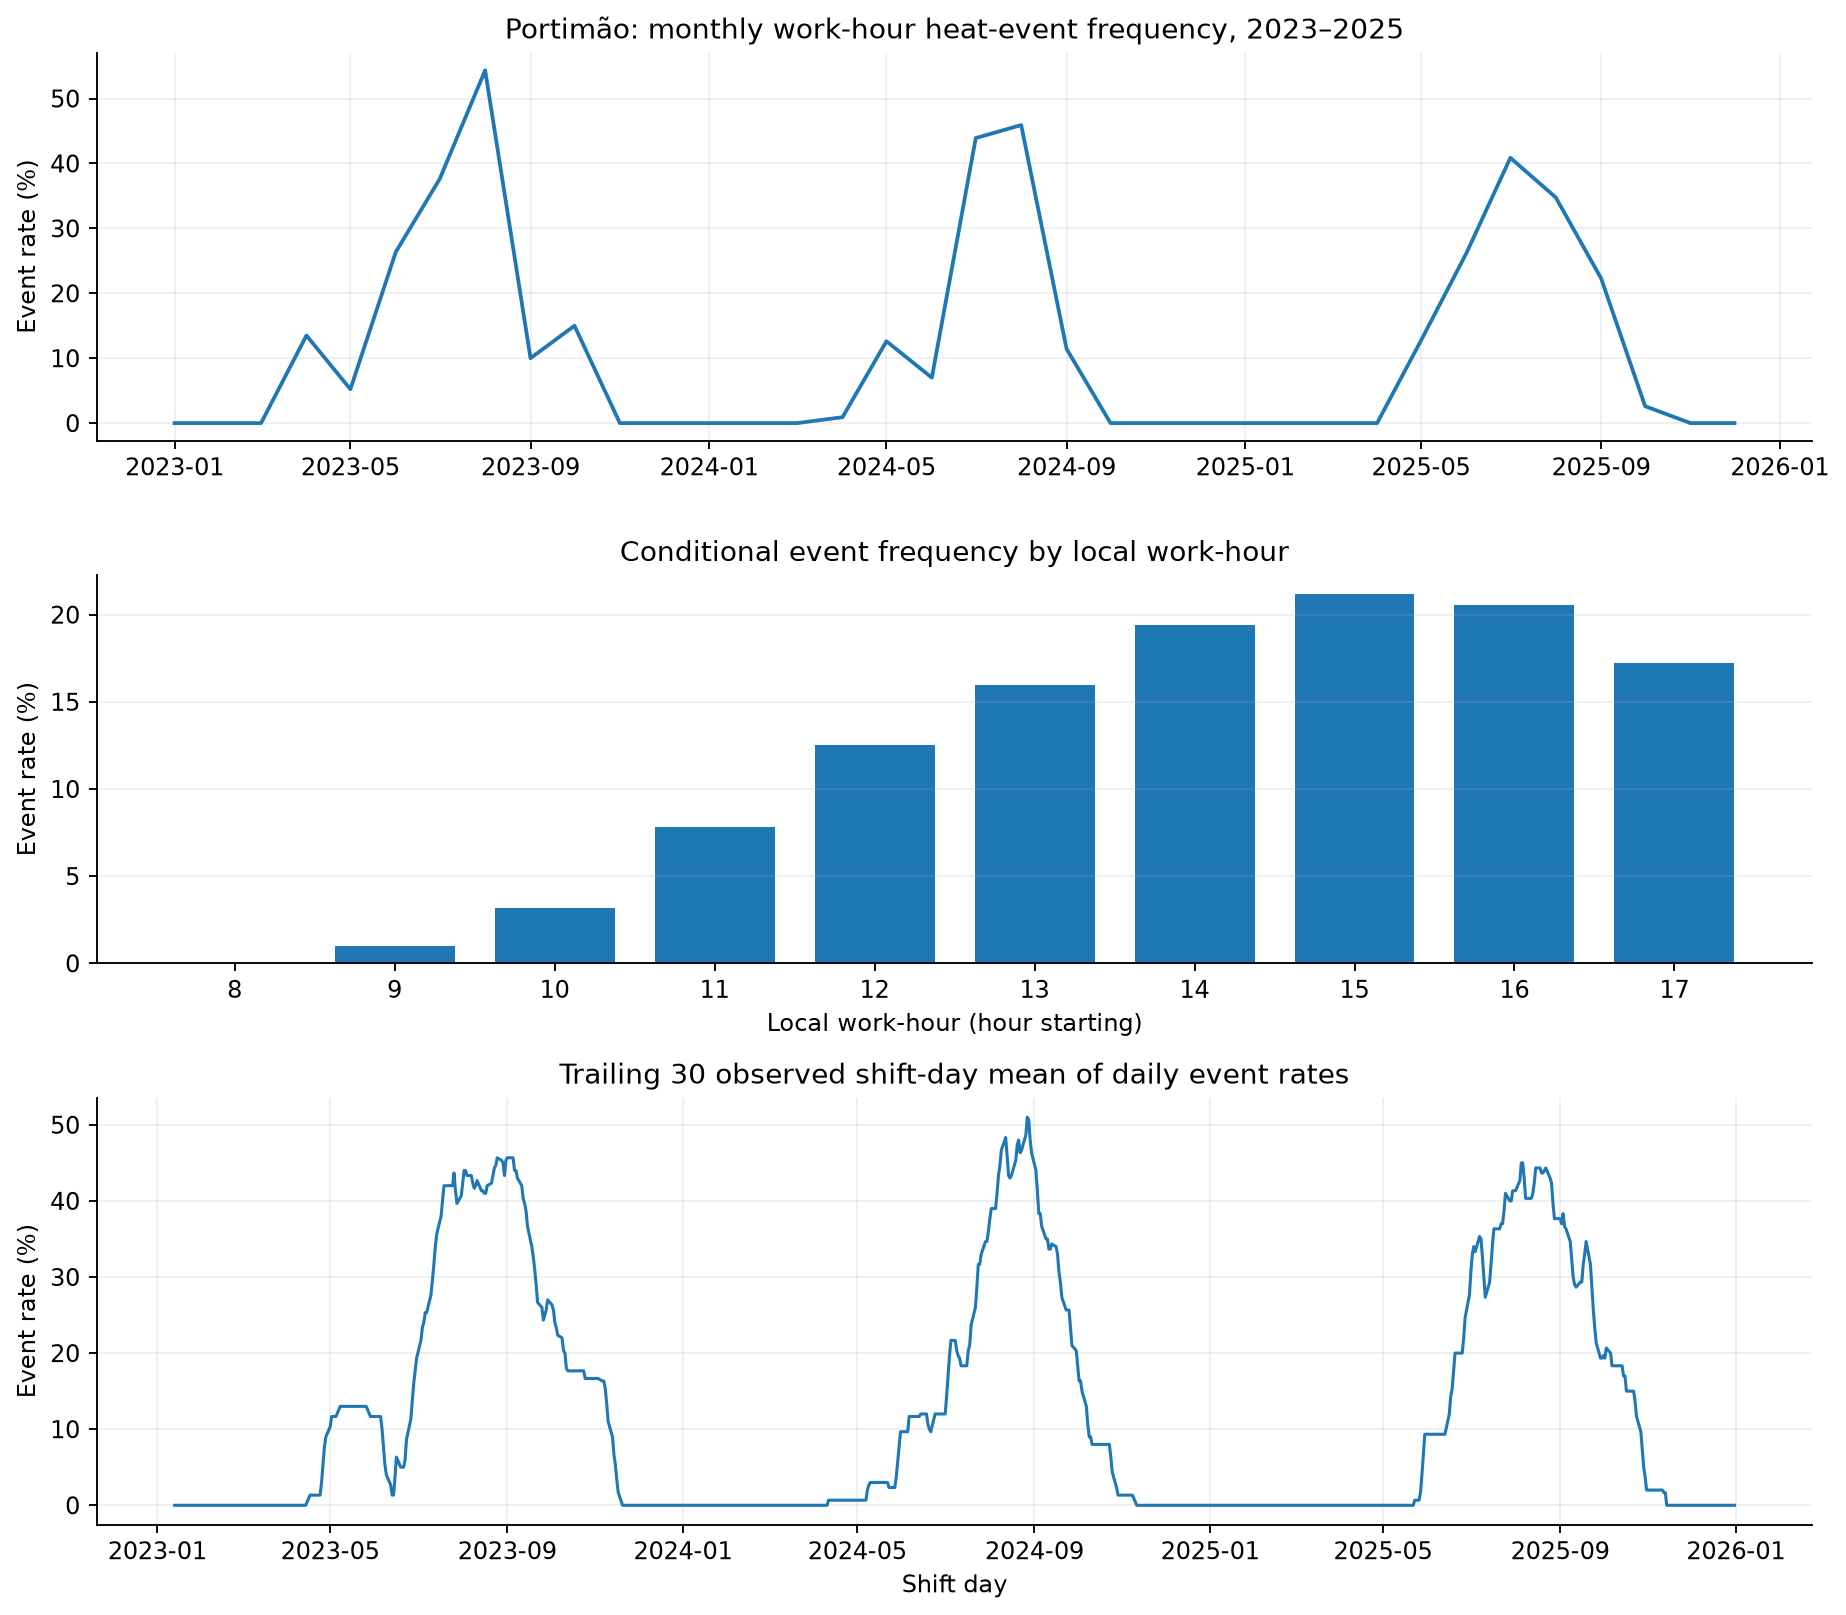

In [111]:
# Display Portimão statistics, yearly counts and temporal profile.
profile_A = describe_city(CITY_A, streams_all[CITY_A])
profiles = pd.DataFrame([profile_A]).set_index('city')
table2 = report_profile_table(CITY_A)
class_years_A = city_class_by_year(CITY_A, streams_all[CITY_A])

print('CITY A — PORTIMÃO | Raw data quality')
display(qa.loc[qa.city.eq(CITY_A)].round(2))
print('CITY A — Table 2: descriptive/event/rolling statistics')
display(table2.round(2))
print('CITY A — observed binary-class counts by year')
display(class_years_A.round(3))
print('CITY A — complete descriptive indicators')
display(pd.Series(profile_A, name=CITY_A).to_frame().round(2))

path_A = city_profile_figure(CITY_A, 'cityA_stream_profile.png')
print('CITY A — Figure 1:', path_A.name)
display(Image(filename=str(path_A), width=950))

## Covilhã summaries

Apply the same summary and plotting functions to Covilhã, using its own observations and the shared target and work-hour calendar.


CITY B — COVILHÃ | Raw data quality


C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\1727683154.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  nanoseconds_per_hour = pd.Timedelta(hours=1).value


,city,variable,n_hours,missing_n,missing_pct,min,median,max,wide_IQR_flags
5,Covilhã,temperature_2m,26304,0,0.0,-3.6,13.5,39.4,0.0
6,Covilhã,relative_humidity_2m,26304,0,0.0,9.0,76.0,100.0,0.0
7,Covilhã,precipitation,26304,0,0.0,0.0,0.0,11.3,5312.0
8,Covilhã,wind_speed_10m,26304,0,0.0,0.0,7.9,33.5,26.0
9,Covilhã,__WORK_HOURS__,7830,0,NaN,NaN,NaN,NaN,NaN


CITY B — Table 3: descriptive/event/rolling statistics


,Indicator,Value,Why it matters
0,Number of observed eligible work-hours,7830.00,Denominator of operational exposure
1,Positive-event rate (%),6.02,Share of work-hours reaching 30 °C
2,Mean work-hour air temperature (°C),16.73,Context for the threshold-based event
3,Maximum consecutive hot-hour episode (h),8.00,Persistence of operational exposure
4,Shift days with ≥3 hot hours (%),10.98,Potential concentration within workdays
5,Maximum 30-shift-day rolling event rate (%),40.33,Observed window of sustained exposure


CITY B — observed binary-class counts by year


,city,year,non_event_hours,event_hours,event_rate_pct
0,Covilhã,2023,2497,103,3.962
1,Covilhã,2024,2480,140,5.344
2,Covilhã,2025,2382,228,8.736


CITY B — complete descriptive indicators


,Covilhã
city,Covilhã
eligible_observed_hours,7830
eligible_unobserved_temperature_hours,0
hot_hours,471
event_rate_pct,6.015326
avg_temperature_C,16.729132
p95_temperature_C,30.6
max_temperature_C,39.4
avg_relative_humidity_pct,62.982631
n_hot_episodes,97


CITY B — Figure 2: cityB_stream_profile.png


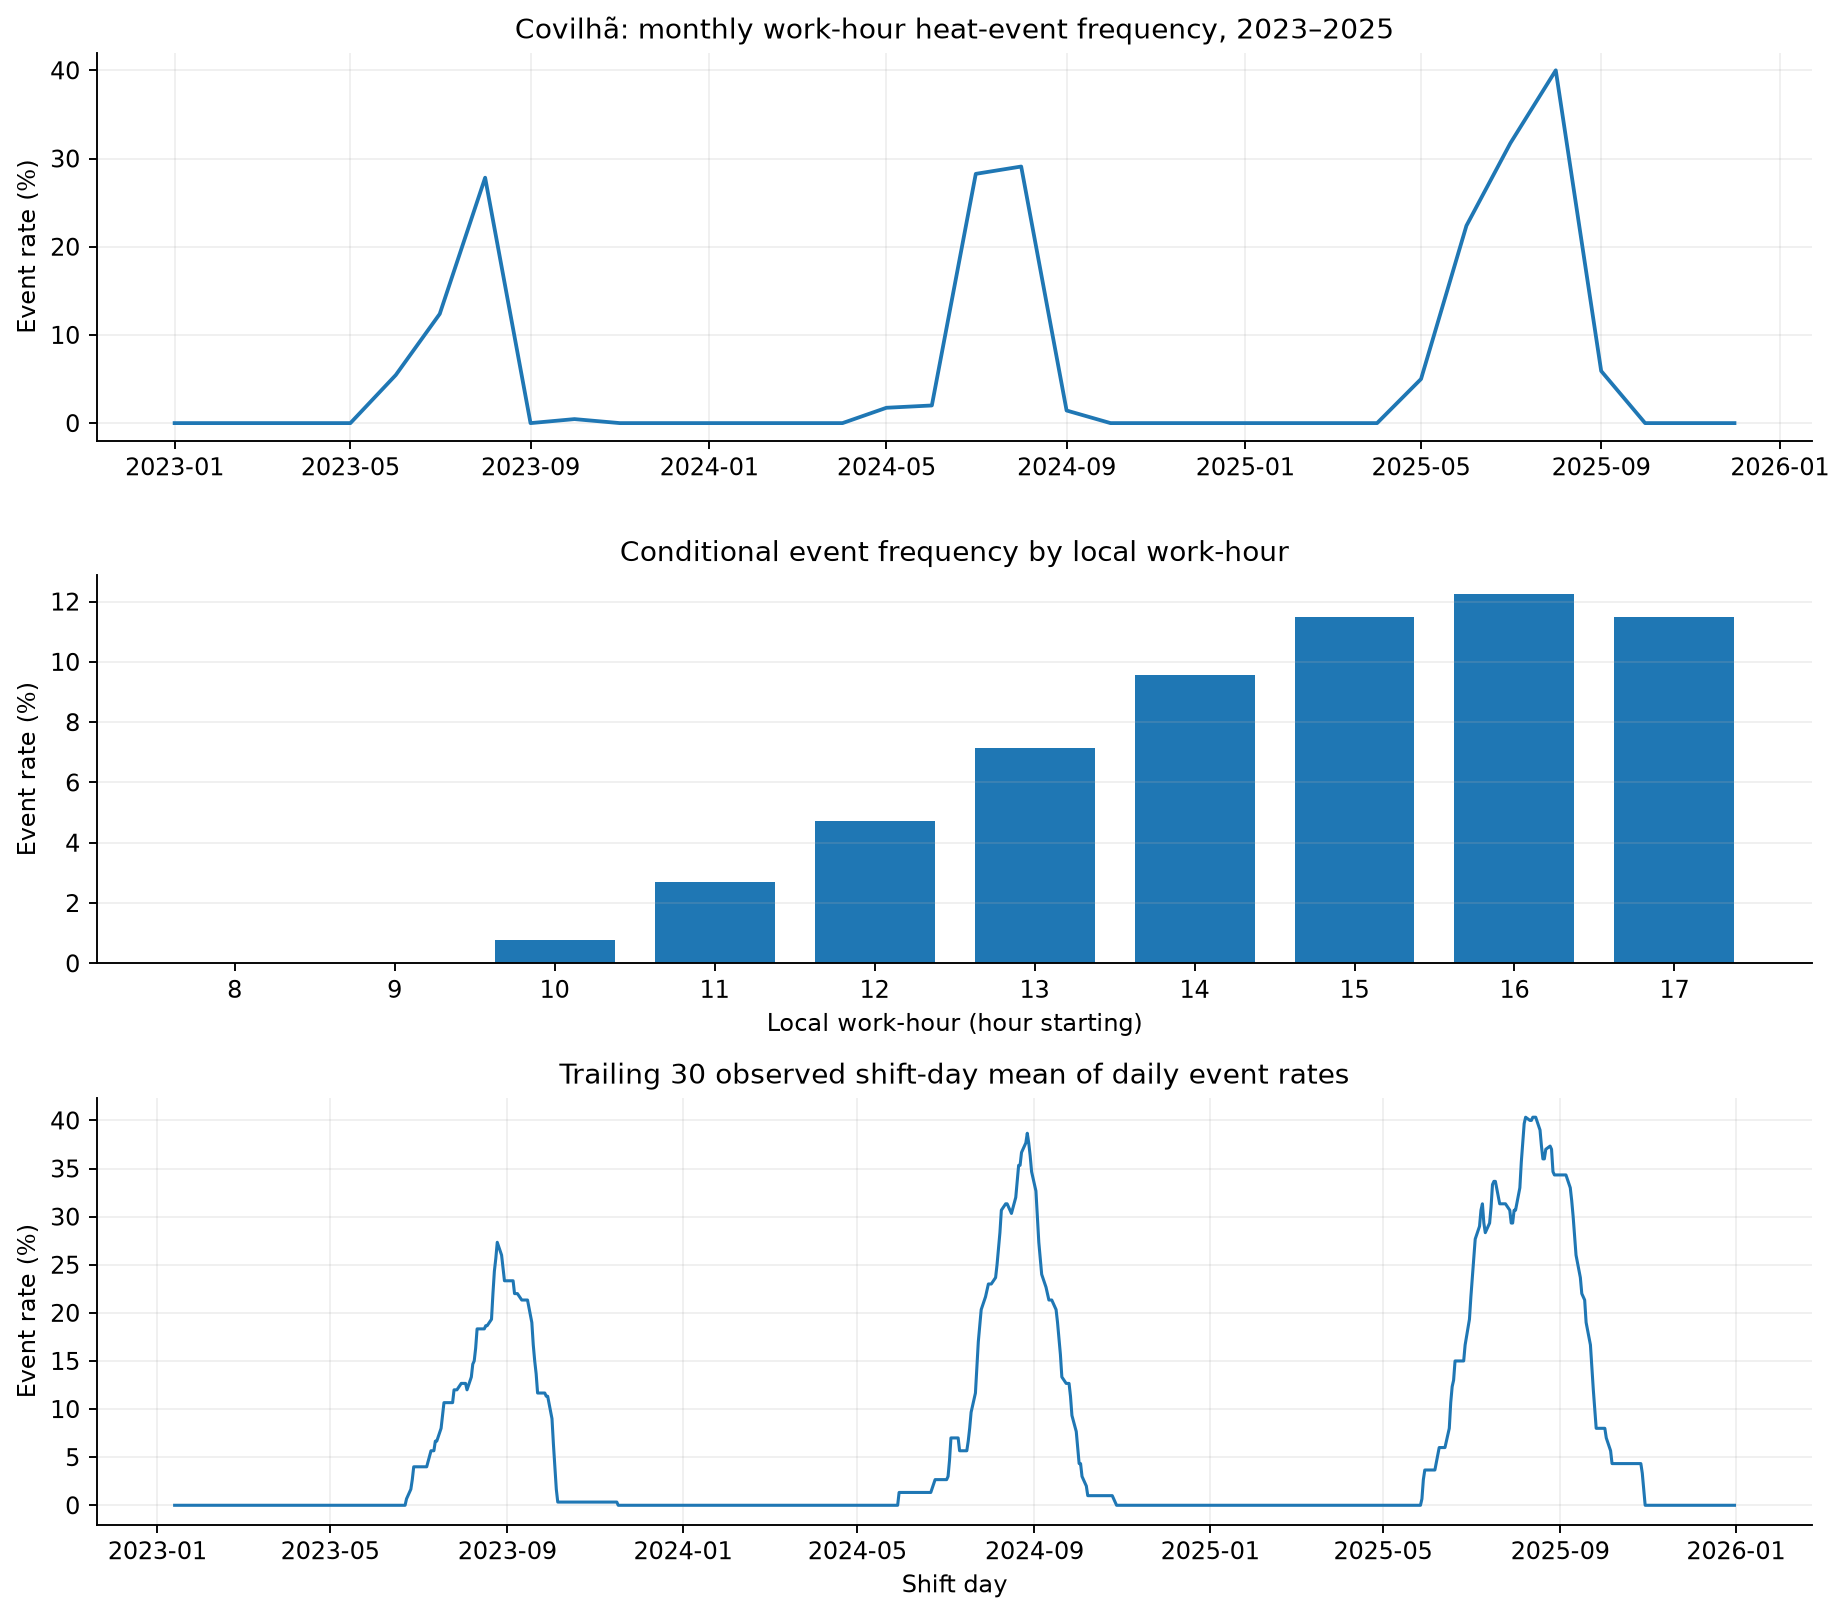

In [112]:
# Display Covilhã statistics, yearly counts and temporal profile.
profile_B = describe_city(CITY_B, streams_all[CITY_B])
profiles.loc[CITY_B] = pd.Series(profile_B)
table3 = report_profile_table(CITY_B)
class_years_B = city_class_by_year(CITY_B, streams_all[CITY_B])

print('CITY B — COVILHÃ | Raw data quality')
display(qa.loc[qa.city.eq(CITY_B)].round(2))
print('CITY B — Table 3: descriptive/event/rolling statistics')
display(table3.round(2))
print('CITY B — observed binary-class counts by year')
display(class_years_B.round(3))
print('CITY B — complete descriptive indicators')
display(pd.Series(profile_B, name=CITY_B).to_frame().round(2))

path_B = city_profile_figure(CITY_B, 'cityB_stream_profile.png')
print('CITY B — Figure 2:', path_B.name)
display(Image(filename=str(path_B), width=950))

## Descriptive city tables and plots

Combine the two city profiles into a table and display their monthly work-hour event rates. Episode calculations end a run when consecutive event timestamps are more than one hour apart.


TABLE 4 — Pre-model business-relevant comparison


city,Portimão,Covilhã
Indicator,,
event_rate_pct,11.89,6.02
max_episode_hours,9.00,8.00
mean_episode_hours,5.48,4.86
shift_days_at_least_3_hot_hours_pct,19.67,10.98
p95_temperature_C,32.70,30.60
episodes_at_least_3h,154.00,86.00
max_rolling_30_shift_day_event_rate_pct,51.00,40.33


Paired yearly event counts (auditable source: city-specific tables above)


,city,year,non_event_hours,event_hours,event_rate_pct
0,Portimão,2023,2245,355,13.654
1,Portimão,2024,2349,271,10.344
2,Portimão,2025,2305,305,11.686
3,Covilhã,2023,2497,103,3.962
4,Covilhã,2024,2480,140,5.344
5,Covilhã,2025,2382,228,8.736


FIGURE 3 — city_comparison.png


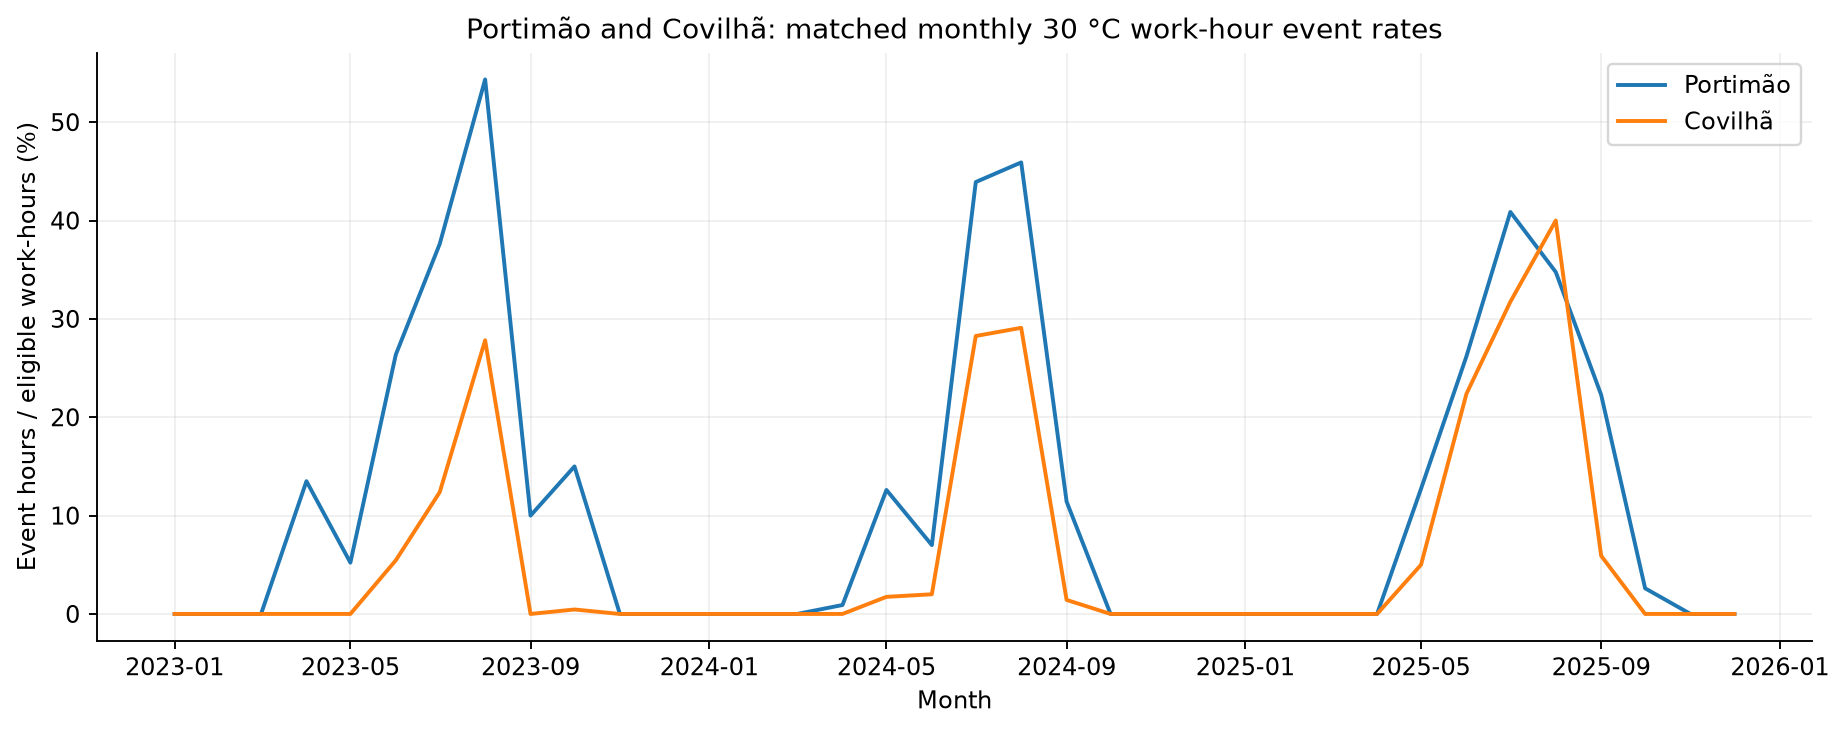

In [113]:
# Combine the city profiles and monthly event rates.
table4 = profiles[['event_rate_pct', 'max_episode_hours', 'mean_episode_hours',
                   'shift_days_at_least_3_hot_hours_pct', 'p95_temperature_C',
                   'episodes_at_least_3h', 'max_rolling_30_shift_day_event_rate_pct']].T
# Ensure the two columns always appear in assigned City A / City B order.
table4 = table4[[CITY_A, CITY_B]]
table4.index.name = 'Indicator'
print('TABLE 4 — Pre-model business-relevant comparison')
display(table4.round(2))

class_years = pd.concat([class_years_A, class_years_B], ignore_index=True)
class_years.to_csv(TABLE_DIR/'event_class_distribution_by_year.csv', index=False)
print('Paired yearly event counts (auditable source: city-specific tables above)')
display(class_years.round(3))

fig, ax = plt.subplots(figsize=(11,4.4))
for city in (CITY_A, CITY_B):
    monthly = monthly_event(streams_all[city])
    ax.plot(monthly.index, 100 * monthly['mean'], label=city, linewidth=1.65)
ax.set(xlabel='Month', ylabel='Event hours / eligible work-hours (%)',
       title='Portimão and Covilhã: matched monthly 30 °C work-hour event rates')
ax.legend()
ax.grid(alpha=.2)
path_comp = save_fig('city_comparison.png')
print('FIGURE 3 —', path_comp.name)
display(Image(filename=str(path_comp), width=950))

### Month/hour and episode summaries

The first plot groups event rates by month and local work hour. The next plots count workdays with at least 1, 3 or 5 event hours and group consecutive-hour episodes by duration.


In [114]:
# O1: work-hour x month exposure calendar, independently normalized per city.
fig, axes = plt.subplots(1, 2, figsize=(12,4.5), sharey=True, constrained_layout=True)
heat_grids = []
for ax, city in zip(axes, CITIES):
    d = eligible_observed(streams_all[city]);
    tab = (100*d.pivot_table(index='local_month', columns='local_hour', values='y_event', aggfunc='mean')
             .reindex(index=range(1,13), columns=range(SHIFT_START, SHIFT_END)))
    heat_grids.append(tab)
maximum = max(1, *(np.nanmax(g.to_numpy()) for g in heat_grids))
for ax,city,tab in zip(axes, CITIES, heat_grids):
    im = ax.imshow(tab.to_numpy(), vmin=0, vmax=maximum, aspect='auto', origin='lower', cmap='YlOrRd')
    ax.set_title(city); ax.set_xlabel('Local work-hour starting at')
    ax.set_xticks(range(10),range(SHIFT_START,SHIFT_END))
    ax.set_yticks(range(12),range(1,13)); ax.set_ylabel('Calendar month')
fig.colorbar(im, ax=axes, label='T2 event rate (% of observed work-hours)', shrink=.9)
# Save without applying tight_layout (constrained_layout handles the colorbar).
p = FIG_DIR/'original_O1_hour_month_risk_map.png'
fig.savefig(p, bbox_inches='tight', facecolor='white', dpi=170); plt.close(fig)

fig, axes = plt.subplots(1,2,figsize=(12,4.3))
summary_hot_days = []
for city in CITIES:
    d=eligible_observed(streams_all[city])
    days=d.groupby('local_date')['y_event'].agg(['sum','count'])
    summary_hot_days.append({'City':city,'≥1 hot hour':100*(days['sum']>=1).mean(),
                              '≥3 hot hours':100*(days['sum']>=3).mean(),
                              '≥5 hot hours':100*(days['sum']>=5).mean()})
shifts=pd.DataFrame(summary_hot_days).set_index('City')
shifts.plot(kind='bar', ax=axes[0], rot=0)
axes[0].set(ylabel='Share of observed shift-days (%)', title='Days affected by multi-hour heat')
axes[0].grid(axis='y',alpha=.2)
spells = {}
for c in CITIES:
    series=episode_frame(streams_all[c])['duration_hours']
    spells[c]=[(series==1).sum(),(series==2).sum(),(series.between(3,4)).sum(),(series>=5).sum()]
spell_counts=pd.DataFrame(spells,index=['1 hour','2 hours','3–4 hours','5+ hours'])
spell_counts.plot(kind='bar',ax=axes[1],rot=0)
axes[1].set(ylabel='Number of observed episodes',title='Length of consecutive hot-hour episodes')
axes[1].grid(axis='y',alpha=.2)
save_fig('original_O2_shift_disruption_and_episode_duration.png')
display(shifts.round(2), spell_counts)
shifts.to_csv(TABLE_DIR/'original_O2_shift_disruption.csv')
spell_counts.to_csv(TABLE_DIR/'original_O2_episode_durations.csv')

C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\1727683154.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  nanoseconds_per_hour = pd.Timedelta(hours=1).value
C:\Users\arpro\AppData\Local\Temp\ipykernel_5228\1727683154.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  nanoseconds_per_hour = pd.Timedelta(hours=1).value


,≥1 hot hour,≥3 hot hours,≥5 hot hours
City,,,
Portimão,21.71,19.67,15.20
Covilhã,12.39,10.98,7.15


,Portimão,Covilhã
1 hour,9,4
2 hours,7,7
3–4 hours,35,30
5+ hours,119,56


### Threshold sensitivity counts

Calculate observed work-hour event counts and rates for thresholds of 28, 30 and 32 °C. These calculations do not train additional models or modify the primary target.


In [115]:
threshold_rows=[]
for c,s in streams_all.items():
    d=eligible_observed(s)
    for threshold in (28.0,30.0,32.0):
        threshold_rows.append({'city':c,'threshold_C':threshold,'observed_work_hours':len(d),
                               'event_hours':int(d['temperature_2m'].ge(threshold).sum()),
                               'event_rate_pct':100*d['temperature_2m'].ge(threshold).mean()})
threshold_sensitivity=pd.DataFrame(threshold_rows)
display(threshold_sensitivity.round(2))
threshold_sensitivity.to_csv(TABLE_DIR/'threshold_sensitivity_descriptive_only.csv',index=False)

,city,threshold_C,observed_work_hours,event_hours,event_rate_pct
0,Portimão,28.0,7830,1442,18.42
1,Portimão,30.0,7830,931,11.89
2,Portimão,32.0,7830,520,6.64
3,Covilhã,28.0,7830,767,9.80
4,Covilhã,30.0,7830,471,6.02
5,Covilhã,32.0,7830,265,3.38


## Model inputs and scaling

Representation A contains four previous-hour weather measurements. Representation B adds temperature change and rolling statistics, the selected humidity/precipitation moving averages, and local forecast hour, for thirteen predictors. The exact columns are listed in `REP_A` and `REP_B`.

For each representation, fit `StandardScaler` to pooled warm-up rows and apply its frozen parameters to both cities. The event label remains separate from the input columns.


In [116]:
SCALED = {}
SCALERS = {}
for representation,names in [('A',REP_A),('B',REP_B)]:
    pooled = np.concatenate([streams[c].loc[warm_times,names].to_numpy(dtype=float)
                             for c in CITIES], axis=0)
    scaler = StandardScaler().fit(pooled)
    SCALERS[representation] = scaler
    for city in CITIES:
        vals = scaler.transform(streams[city][names].to_numpy(dtype=float))
        if not np.isfinite(vals).all(): raise ValueError(f'Invalid scaled values: {city}/{representation}')
        SCALED[(city,representation)] = pd.DataFrame(vals,index=common_times,columns=names)
print('Frozen pooled-warm-up scalers fitted for A/B; features:', len(REP_A),len(REP_B))

Frozen pooled-warm-up scalers fitted for A/B; features: 4 13


### Learner construction

`make_model` creates a fresh River GaussianNB, logistic regression, Hoeffding Tree, bagging ensemble or adaptive random forest. `MODEL_CONFIG` records parameters, and the cell verifies that each learner exposes `predict_one` and `learn_one`.


In [117]:
try:
    from river import naive_bayes, linear_model, tree, ensemble, forest, optim
except ImportError as exc:
    raise ImportError(
        'The FIVE mandatory River learners are required. Install River into this notebook kernel: '
        '%pip install "river>=0.23,<0.25"\nThen restart the kernel and Run All.'
    ) from exc

MODEL_NAMES = ['GaussianNB','Online Logistic','Hoeffding Tree','Online Bagging','Adaptive Random Forest']
MODEL_CONFIG = {
 'GaussianNB': 'River GaussianNB; default, online class-conditional Gaussian statistics',
 'Online Logistic': 'River LogisticRegression; SGD(0.05), default L2 configuration',
 'Hoeffding Tree': 'River HoeffdingTreeClassifier; grace_period=50, delta=0.001, tau=0.10, leaf_prediction=mc',
 'Online Bagging': 'River BaggingClassifier; 5 HoeffdingTree base members, Poisson(1), seed=42',
 'Adaptive Random Forest': 'River ARFClassifier; 5 trees, sqrt feature subsampling, lambda=6, '
                           'grace_period=50, delta=0.001, tau=0.10, mc leaves, seed=42'
}
def base_tree():
    return tree.HoeffdingTreeClassifier(grace_period=50, delta=1e-3, tau=.10, leaf_prediction='mc')

def make_model(name):
    if name=='GaussianNB': return naive_bayes.GaussianNB()
    if name=='Online Logistic': return linear_model.LogisticRegression(optimizer=optim.SGD(.05))
    if name=='Hoeffding Tree': return base_tree()
    if name=='Online Bagging': return ensemble.BaggingClassifier(model=base_tree(), n_models=ENSEMBLE_SIZE, seed=RANDOM_SEED)
    if name=='Adaptive Random Forest':
        return forest.ARFClassifier(n_models=ENSEMBLE_SIZE, max_features='sqrt', lambda_value=6,
                                    leaf_prediction='mc', grace_period=50, delta=1e-3, tau=.10,
                                    seed=RANDOM_SEED)
    raise KeyError(name)

# Fail before a long experiment if a River version removed/renamed an expected implementation.
for _name in MODEL_NAMES:
    _instance = make_model(_name)
    assert hasattr(_instance, 'predict_one') and hasattr(_instance, 'learn_one')
print('All 5 River learners instantiated successfully. River:', package_version('river'))
table5 = pd.DataFrame({'Model':MODEL_NAMES,'Main configuration / parameters':[MODEL_CONFIG[n] for n in MODEL_NAMES]})
display(table5)

All 5 River learners instantiated successfully. River: 0.23.0


,Model,Main configuration / parameters
0,GaussianNB,"River GaussianNB; default, online class-condit..."
1,Online Logistic,"River LogisticRegression; SGD(0.05), default L..."
2,Hoeffding Tree,River HoeffdingTreeClassifier; grace_period=50...
3,Online Bagging,River BaggingClassifier; 5 HoeffdingTree base ...
4,Adaptive Random Forest,"River ARFClassifier; 5 trees, sqrt feature sub..."


### Sequential evaluation

`prequential_run` trains on warm-up events without scoring. Each later event is predicted, scored and then learned. `StreamingBinaryEvaluator` maintains binary confusion counts, cumulative metrics and a rolling Macro-F1 window. Prediction and update durations are timed separately; `None` predictions are counted and mapped to class 0.


In [118]:
def metrics_from_counts(tn, fp, fn, tp):
    n = int(tn+fp+fn+tp)
    prec1 = tp/(tp+fp) if (tp+fp) else 0.0
    rec1 = tp/(tp+fn) if (tp+fn) else 0.0
    prec0 = tn/(tn+fn) if (tn+fn) else 0.0
    rec0 = tn/(tn+fp) if (tn+fp) else 0.0
    f1_1 = 2*prec1*rec1/(prec1+rec1) if (prec1+rec1) else 0.0
    f1_0 = 2*prec0*rec0/(prec0+rec0) if (prec0+rec0) else 0.0
    return {'accuracy':(tp+tn)/n if n else 0.0,
            'macro_f1':(f1_0+f1_1)/2,
            'precision_event':prec1,'recall_event':rec1,'event_f1':f1_1,
            'specificity':rec0, 'n_evaluated':n,
            'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)}

class StreamingBinaryEvaluator:
    def __init__(self,window=ROLLING_SCORE_WINDOW):
        self.cm = np.zeros((2,2),dtype=np.int64)  # [truth,prediction]
        self.window = deque(maxlen=int(window))
    def update(self,y,p):
        y,p = int(y),int(p)
        assert y in (0,1) and p in (0,1)
        self.cm[y,p]+=1
        self.window.append((y,p))
    def snapshot(self):
        tn,fp,fn,tp = self.cm[0,0],self.cm[0,1],self.cm[1,0],self.cm[1,1]
        out=metrics_from_counts(tn,fp,fn,tp)
        if self.window:
            recent = np.zeros((2,2),dtype=np.int64)
            for y,p in self.window: recent[y,p]+=1
            out['rolling_macro_f1']=metrics_from_counts(recent[0,0],recent[0,1],
                                                       recent[1,0],recent[1,1])['macro_f1']
        else: out['rolling_macro_f1']=np.nan
        return out

# Known-value accounting test, before modelling.
a=StreamingBinaryEvaluator()
for yy,pp in [(1,1),(1,0),(0,0),(0,1)]:a.update(yy,pp)
assert a.snapshot()['accuracy']==.5
assert a.snapshot()['TP']==a.snapshot()['TN']==a.snapshot()['FP']==a.snapshot()['FN']==1
print('PASS: streaming confusion matrix and binary metrics unit tests')

def events_for(city,representation):
    x = SCALED[(city,representation)]
    labels = streams[city]['y_event']
    for ts,row in x.iterrows():
        yield (ts,{key:float(val) for key,val in row.items()},int(labels.loc[ts]))

def prequential_run(city,representation,name):
    # Fresh instance per experiment. NEVER share model states across cities/reps.
    model=make_model(name)
    observations=events_for(city,representation)
    for j in range(cut):
        ts,x,y = next(observations)
        model.learn_one(x,y)
    ev=StreamingBinaryEvaluator()
    pred_ns=upd_ns=0
    cold_outputs=0
    history=[]
    for k,(ts,x,y) in enumerate(observations,start=1):
        t0=time.perf_counter_ns()
        raw_pred=model.predict_one(x)
        pred_ns+=time.perf_counter_ns()-t0
        if raw_pred is None:
            cold_outputs+=1
            p=0
        else:
            p=int(raw_pred)
        ev.update(y,p)  # EVALUATE before the current y can reach learn_one
        t0=time.perf_counter_ns()
        model.learn_one(x,y)
        upd_ns+=time.perf_counter_ns()-t0
        n=k
        if n==1 or n%CHECKPOINT_EVERY==0 or n==len(eval_times):
            history.append({'timestamp':ts,'evaluated':n,**ev.snapshot()})
    s=ev.snapshot()
    assert s['n_evaluated']==len(eval_times)
    return {'summary':{**s,'city':city,'representation':representation,'model':name,
                       'pred_ms_per_event':pred_ns/1e6/len(eval_times),
                       'update_ms_per_event':upd_ns/1e6/len(eval_times),
                       'cold_outputs':cold_outputs},
            'history':pd.DataFrame(history),
            'confusion':ev.cm.copy()}

PASS: streaming confusion matrix and binary metrics unit tests


### Run the experiments

Run a fresh learner for each city × representation × model combination. The cell collects twenty result rows, checks evaluation counts and displays the metrics.


In [119]:
results={}; all_rows=[]
start_run=time.perf_counter()
for city in CITIES:
    for representation in ('A','B'):
        for model_name in MODEL_NAMES:
            tic=time.perf_counter()
            r=prequential_run(city,representation,model_name)
            results[(city,representation,model_name)]=r
            all_rows.append(r['summary'])
            print(f'{city:9s} | {representation} | {model_name:24s} | '
                  f'{time.perf_counter()-tic:6.1f}s | n={r["summary"]["n_evaluated"]:,}')
full_results=pd.DataFrame(all_rows)
assert len(full_results)==20
assert full_results.groupby(['city','representation'])['n_evaluated'].nunique().eq(1).all()
assert full_results['n_evaluated'].eq(len(eval_times)).all()
full_results.to_csv(TABLE_DIR/'complete_20_run_results.csv',index=False)
print(f'All full suites completed in {(time.perf_counter()-start_run)/60:.1f} min.')
display(full_results[['city','representation','model','accuracy','macro_f1','precision_event',
                       'recall_event','pred_ms_per_event','update_ms_per_event']].round(4))

Portimão  | A | GaussianNB               |    0.6s | n=6,264
Portimão  | A | Online Logistic          |    0.2s | n=6,264
Portimão  | A | Hoeffding Tree           |    0.3s | n=6,264
Portimão  | A | Online Bagging           |    0.5s | n=6,264
Portimão  | A | Adaptive Random Forest   |    1.0s | n=6,264
Portimão  | B | GaussianNB               |    0.7s | n=6,264
Portimão  | B | Online Logistic          |    0.2s | n=6,264
Portimão  | B | Hoeffding Tree           |    0.3s | n=6,264
Portimão  | B | Online Bagging           |    0.9s | n=6,264
Portimão  | B | Adaptive Random Forest   |    1.5s | n=6,264
Covilhã   | A | GaussianNB               |    0.6s | n=6,264
Covilhã   | A | Online Logistic          |    0.2s | n=6,264
Covilhã   | A | Hoeffding Tree           |    0.3s | n=6,264
Covilhã   | A | Online Bagging           |    0.5s | n=6,264
Covilhã   | A | Adaptive Random Forest   |    1.0s | n=6,264
Covilhã   | B | GaussianNB               |    0.7s | n=6,264
Covilhã   | B | Online L

,city,representation,model,accuracy,macro_f1,precision_event,recall_event,pred_ms_per_event,update_ms_per_event
0,Portimão,A,GaussianNB,0.8838,0.4692,0.0000,0.0000,0.0545,0.0027
1,Portimão,A,Online Logistic,0.9569,0.8957,0.8103,0.8214,0.0015,0.0052
2,Portimão,A,Hoeffding Tree,0.9706,0.9240,0.9317,0.8063,0.0050,0.0064
3,Portimão,A,Online Bagging,0.9748,0.9385,0.8926,0.8901,0.0203,0.0278
4,Portimão,A,Adaptive Random Forest,0.9674,0.9203,0.8649,0.8530,0.0270,0.0747
5,Portimão,B,GaussianNB,0.9345,0.7954,0.9297,0.4725,0.0640,0.0048
6,Portimão,B,Online Logistic,0.9612,0.9056,0.8326,0.8338,0.0019,0.0074
7,Portimão,B,Hoeffding Tree,0.9717,0.9271,0.9339,0.8146,0.0051,0.0126
8,Portimão,B,Online Bagging,0.9727,0.9348,0.8660,0.9052,0.0248,0.0697
9,Portimão,B,Adaptive Random Forest,0.9679,0.9196,0.8869,0.8297,0.0362,0.1154


### Three-MA feature comparison

Compare the fixed 8-feature and 11-feature versions using the same timestamps, labels, warm-up preprocessing and learner settings. The three added inputs are Humidity MA3 L24, Precip MA 24h and Humidity MA 3h.

The tables display scores and confusion counts for each version. Score differences are `with − without`, in percentage points.


In [120]:
# Controlled comparison: the only difference is the three selected MA predictors.
ma_baseline_features = [name for name in REP_B_PREVIOUS if name not in INITIAL_MA_FEATURES]
ma_augmented_features = list(REP_B_PREVIOUS)
assert len(ma_baseline_features) == 8 and len(ma_augmented_features) == 11
assert set(ma_augmented_features) - set(ma_baseline_features) == set(INITIAL_MA_FEATURES)
assert TARGET_VARIABLE not in ma_augmented_features
assert not DEVELOPMENT_MODE, 'Run the full dataset for the feature comparison.'

# StandardScaler operates per column, so subsetting B preserves the exact scaling
# of all shared features without fitting anything to evaluation observations.
ma_representations = {
    'B_without_MAs': ma_baseline_features,
    'B_with_MAs': ma_augmented_features,
}
for ma_city in CITIES:
    for ma_representation, ma_features in ma_representations.items():
        SCALED[(ma_city, ma_representation)] = SCALED[(ma_city, 'B')][ma_features].copy()
    pd.testing.assert_frame_equal(
        SCALED[(ma_city, 'B_without_MAs')],
        SCALED[(ma_city, 'B_with_MAs')][ma_baseline_features],
    )

ma_ablation_rows = []
for ma_city in CITIES:
    for ma_model in MODEL_NAMES:
        for ma_representation in ma_representations:
            # Each call creates a fresh model with the notebook's fixed seed.
            ma_run = prequential_run(ma_city, ma_representation, ma_model)
            ma_ablation_rows.append(ma_run['summary'])
        print(f'Completed MA comparison: {ma_city} | {ma_model}')
ma_ablation_results = pd.DataFrame(ma_ablation_rows)
assert len(ma_ablation_results) == 2 * len(CITIES) * len(MODEL_NAMES)
assert ma_ablation_results.n_evaluated.eq(len(eval_times)).all()

ma_without = ma_ablation_results.query('representation == "B_without_MAs"').set_index(['city', 'model'])
ma_with = ma_ablation_results.query('representation == "B_with_MAs"').set_index(['city', 'model'])
pd.testing.assert_series_equal(
    ma_without['TP'] + ma_without['FN'], ma_with['TP'] + ma_with['FN'], check_names=False
)
ma_ablation_comparison = pd.DataFrame(index=ma_without.index)
for ma_metric in ['accuracy', 'macro_f1', 'precision_event', 'recall_event', 'event_f1']:
    ma_ablation_comparison[f'{ma_metric}_without'] = ma_without[ma_metric]
    ma_ablation_comparison[f'{ma_metric}_with'] = ma_with[ma_metric]
    ma_ablation_comparison[f'{ma_metric}_delta_pp'] = 100 * (
        ma_with[ma_metric] - ma_without[ma_metric]
    )
for ma_count in ['FN', 'FP', 'TP', 'TN']:
    ma_ablation_comparison[f'{ma_count}_without'] = ma_without[ma_count]
    ma_ablation_comparison[f'{ma_count}_with'] = ma_with[ma_count]
    ma_ablation_comparison[f'{ma_count}_delta'] = ma_with[ma_count] - ma_without[ma_count]
ma_ablation_comparison['n_evaluated'] = ma_without.n_evaluated
ma_ablation_comparison = ma_ablation_comparison.reset_index()

print('Without = original B (8 features); with = B plus the 3 selected MAs (11 features).')
print('Added features:', ', '.join(INITIAL_MA_FEATURES))
print(f'Same {len(warm_times):,} warm-up hours and {len(eval_times):,} evaluation hours per city.')
print('Delta pp = with minus without, in percentage points. Negative FN/FP deltas mean fewer errors.')
for ma_city in CITIES:
    ma_city_results = ma_ablation_comparison.loc[ma_ablation_comparison.city.eq(ma_city)].set_index('model')
    ma_summary = pd.DataFrame(index=ma_city_results.index)
    for ma_metric, ma_title in [('macro_f1', 'Macro-F1'), ('recall_event', 'Event recall'),
                                ('accuracy', 'Accuracy')]:
        ma_summary[f'{ma_title} without (%)'] = 100 * ma_city_results[f'{ma_metric}_without']
        ma_summary[f'{ma_title} with (%)'] = 100 * ma_city_results[f'{ma_metric}_with']
        ma_summary[f'{ma_title} change (pp)'] = ma_city_results[f'{ma_metric}_delta_pp']
    display(Markdown(f'**Added MA features — {ma_city}**'))
    display(ma_summary.style.format('{:.2f}'))
    display(ma_city_results[['precision_event_without', 'precision_event_with',
                             'event_f1_without', 'event_f1_with',
                             'FN_without', 'FN_with', 'FN_delta',
                             'FP_without', 'FP_with', 'FP_delta']].round(4))

ma_ablation_counts = pd.DataFrame([
    {'metric': label,
     'increased': int((ma_ablation_comparison[f'{metric}_delta_pp'] > 1e-9).sum()),
     'unchanged': int((ma_ablation_comparison[f'{metric}_delta_pp'].abs() <= 1e-9).sum()),
     'decreased': int((ma_ablation_comparison[f'{metric}_delta_pp'] < -1e-9).sum())}
    for metric, label in [('macro_f1', 'Macro-F1'), ('recall_event', 'Event recall'), ('accuracy', 'Accuracy')]
]
)
display(ma_ablation_counts)


Completed MA comparison: Portimão | GaussianNB
Completed MA comparison: Portimão | Online Logistic
Completed MA comparison: Portimão | Hoeffding Tree
Completed MA comparison: Portimão | Online Bagging
Completed MA comparison: Portimão | Adaptive Random Forest
Completed MA comparison: Covilhã | GaussianNB
Completed MA comparison: Covilhã | Online Logistic
Completed MA comparison: Covilhã | Hoeffding Tree
Completed MA comparison: Covilhã | Online Bagging
Completed MA comparison: Covilhã | Adaptive Random Forest
Without = original B (8 features); with = B plus the 3 selected MAs (11 features).
Added features: humidity_mean_3h_lag24, precipitation_mean_24h, humidity_mean_3h
Same 1,566 warm-up hours and 6,264 evaluation hours per city.
Delta pp = with minus without, in percentage points. Negative FN/FP deltas mean fewer errors.


**Added MA features — Portimão**

,Macro-F1 without (%),Macro-F1 with (%),Macro-F1 change (pp),Event recall without (%),Event recall with (%),Event recall change (pp),Accuracy without (%),Accuracy with (%),Accuracy change (pp)
model,,,,,,,,,
GaussianNB,47.06,75.31,28.25,0.14,37.91,37.77,88.39,92.67,4.28
Online Logistic,89.98,89.86,-0.13,82.01,82.42,0.41,95.90,95.82,-0.08
Hoeffding Tree,92.71,92.71,0.00,81.46,81.46,0.00,97.17,97.17,0.00
Online Bagging,94.30,93.01,-1.29,88.74,89.97,1.24,97.69,97.06,-0.62
Adaptive Random Forest,93.32,93.46,0.14,87.64,86.40,-1.24,97.27,97.37,0.10


,precision_event_without,precision_event_with,event_f1_without,event_f1_with,FN_without,FN_with,FN_delta,FP_without,FP_with,FP_delta
model,,,,,,,,,,
GaussianNB,1.0000,0.9753,0.0027,0.5460,727,452,-275,0,7,7
Online Logistic,0.8257,0.8174,0.8229,0.8208,131,128,-3,126,134,8
Hoeffding Tree,0.9339,0.9339,0.8701,0.8701,135,135,0,42,42,0
Online Bagging,0.9111,0.8551,0.8991,0.8768,82,73,-9,63,111,48
Adaptive Random Forest,0.8873,0.9050,0.8818,0.8840,90,99,9,81,66,-15


**Added MA features — Covilhã**

,Macro-F1 without (%),Macro-F1 with (%),Macro-F1 change (pp),Event recall without (%),Event recall with (%),Event recall change (pp),Accuracy without (%),Accuracy with (%),Accuracy change (pp)
model,,,,,,,,,
GaussianNB,81.60,83.46,1.86,73.05,84.87,11.82,94.91,95.00,0.10
Online Logistic,90.44,90.26,-0.18,82.27,82.03,-0.24,97.59,97.54,-0.05
Hoeffding Tree,91.16,91.16,0.00,85.82,85.82,0.00,97.72,97.72,0.00
Online Bagging,94.84,94.88,0.04,87.47,87.00,-0.47,98.74,98.75,0.02
Adaptive Random Forest,92.83,91.29,-1.54,83.22,80.14,-3.07,98.26,97.89,-0.37


,precision_event_without,precision_event_with,event_f1_without,event_f1_with,FN_without,FN_with,FN_delta,FP_without,FP_with,FP_delta
model,,,,,,,,,,
GaussianNB,0.6012,0.5905,0.6596,0.6964,114,64,-50,205,249,44
Online Logistic,0.8208,0.8165,0.8217,0.8184,75,76,1,76,78,2
Hoeffding Tree,0.8139,0.8139,0.8354,0.8354,60,60,0,83,83,0
Online Bagging,0.9343,0.9412,0.9035,0.9042,53,55,2,26,23,-3
Adaptive Random Forest,0.9026,0.8760,0.8659,0.8370,71,84,13,38,48,10


,metric,increased,unchanged,decreased
0,Macro-F1,4,2,4
1,Event recall,4,2,4
2,Accuracy,4,2,4


### Candidate feature trials

Starting from the fixed previous 11-feature representation, add Humidity MA 24h, Humidity MA3 L8 or local hour individually, then all three together. Extra medians and scaling parameters are fitted on pooled warm-up rows. Shared input columns retain their original preprocessing.

Each trial creates a fresh learner and displays before/after metrics. The active thirteen-feature `REP_B` remains separate from these fixed trial definitions.


In [121]:
# Historical candidate tests against previous B (11); the active model B has 13 features.
candidate_names = ['humidity_mean_24h', 'humidity_mean_3h_lag8', 'local_hour']
candidate_variants = {
    'Previous B (11)': [],
    '+ Humidity MA 24h': ['humidity_mean_24h'],
    '+ Humidity MA3 L8': ['humidity_mean_3h_lag8'],
    '+ Local hour': ['local_hour'],
    '+ All three': list(candidate_names),
}
assert len(REP_B_PREVIOUS) == 11 and not set(candidate_names).intersection(REP_B_PREVIOUS)
assert TARGET_VARIABLE not in REP_B + candidate_names
assert not DEVELOPMENT_MODE, 'Use the full dataset for candidate testing.'

candidate_raw = {}
for candidate_city in CITIES:
    candidate_history = raw[candidate_city]['relative_humidity_2m'].ffill(limit=3)
    candidate_raw[candidate_city] = pd.DataFrame({
        'humidity_mean_24h': candidate_history.rolling(24, min_periods=24).mean().shift(1),
        'humidity_mean_3h_lag8': candidate_history.rolling(3, min_periods=3).mean().shift(8),
        # The hour being forecast is known at decision time, so no lag is needed.
        'local_hour': raw[candidate_city].index.tz_convert(TZ_LOCAL).hour,
    }, index=raw[candidate_city].index).reindex(common_times)

# Fit all extra preprocessing on pooled warm-up only; leave shared B columns unchanged.
candidate_pooled_warm = pd.concat([candidate_raw[city].loc[warm_times, candidate_names]
                                 for city in CITIES])
candidate_medians = candidate_pooled_warm.median()
assert candidate_medians.notna().all()
candidate_scaler = StandardScaler().fit(candidate_pooled_warm.fillna(candidate_medians))
for candidate_city in CITIES:
    candidate_extra = pd.DataFrame(
        candidate_scaler.transform(candidate_raw[candidate_city].fillna(candidate_medians)),
        index=common_times, columns=candidate_names,
    )
    assert np.isfinite(candidate_extra.to_numpy()).all()
    for candidate_variant, candidate_added in candidate_variants.items():
        candidate_values = pd.concat([SCALED[(candidate_city, 'B')][REP_B_PREVIOUS],
                                      candidate_extra[candidate_added]], axis=1)
        pd.testing.assert_frame_equal(candidate_values[REP_B_PREVIOUS], SCALED[(candidate_city, 'B')][REP_B_PREVIOUS])
        SCALED[(candidate_city, candidate_variant)] = candidate_values

candidate_run_rows = []
for candidate_city in CITIES:
    for candidate_model in MODEL_NAMES:
        for candidate_variant in candidate_variants:
            candidate_run = prequential_run(candidate_city, candidate_variant, candidate_model)
            candidate_run_rows.append(candidate_run['summary'])
        print(f'Completed candidate tests: {candidate_city} | {candidate_model}')
candidate_results = pd.DataFrame(candidate_run_rows)
assert len(candidate_results) == len(CITIES) * len(MODEL_NAMES) * len(candidate_variants)
assert candidate_results.n_evaluated.eq(len(eval_times)).all()
candidate_base = candidate_results.loc[candidate_results.representation.eq('Previous B (11)')]
candidate_base = candidate_base.set_index(['city', 'model'])

candidate_delta_rows = []
for candidate_record in candidate_results.to_dict(orient='records'):
    if candidate_record['representation'] == 'Previous B (11)':
        continue
    candidate_reference = candidate_base.loc[(candidate_record['city'], candidate_record['model'])]
    assert candidate_record['TP'] + candidate_record['FN'] == candidate_reference.TP + candidate_reference.FN
    candidate_delta = {'city': candidate_record['city'], 'model': candidate_record['model'],
                       'variant': candidate_record['representation'], 'n_evaluated': len(eval_times)}
    for candidate_metric in ['macro_f1', 'recall_event', 'precision_event', 'accuracy', 'event_f1']:
        candidate_delta[f'{candidate_metric}_baseline'] = float(candidate_reference[candidate_metric])
        candidate_delta[f'{candidate_metric}_candidate'] = candidate_record[candidate_metric]
        candidate_delta[f'{candidate_metric}_delta_pp'] = 100 * (
            candidate_record[candidate_metric] - candidate_reference[candidate_metric])
    for candidate_count in ['FN', 'FP', 'TP', 'TN']:
        candidate_delta[f'{candidate_count}_baseline'] = int(candidate_reference[candidate_count])
        candidate_delta[f'{candidate_count}_candidate'] = candidate_record[candidate_count]
    candidate_delta_rows.append(candidate_delta)
candidate_comparison = pd.DataFrame(candidate_delta_rows)

print(f'Same {len(warm_times):,} warm-up and {len(eval_times):,} evaluation hours per city; seed {RANDOM_SEED}.')
print('Each trial starts a fresh learner. Score changes are percentage points relative to previous B (11 features).')
candidate_summary_rows = []
for candidate_variant in list(candidate_variants)[1:]:
    for candidate_city in CITIES:
        candidate_subset = candidate_comparison.loc[
            candidate_comparison.variant.eq(candidate_variant) & candidate_comparison.city.eq(candidate_city)
        ].set_index('model')
        candidate_view = pd.DataFrame(index=candidate_subset.index)
        for candidate_metric, candidate_label in [('macro_f1', 'Macro-F1'), ('recall_event', 'Recall')]:
            candidate_view[f'{candidate_label} baseline (%)'] = 100 * candidate_subset[f'{candidate_metric}_baseline']
            candidate_view[f'{candidate_label} candidate (%)'] = 100 * candidate_subset[f'{candidate_metric}_candidate']
            candidate_view[f'{candidate_label} change (pp)'] = candidate_subset[f'{candidate_metric}_delta_pp']
        candidate_view['FN baseline'] = candidate_subset.FN_baseline
        candidate_view['FN candidate'] = candidate_subset.FN_candidate
        candidate_view['FP baseline'] = candidate_subset.FP_baseline
        candidate_view['FP candidate'] = candidate_subset.FP_candidate
        display(Markdown(f'**{candidate_city} — {candidate_variant}**'))
        display(candidate_view.style.format({column: '{:.2f}' for column in candidate_view.columns
                                             if '(%)' in column or '(pp)' in column}))
        candidate_delta_f1 = candidate_subset.macro_f1_delta_pp
        candidate_summary_rows.append({
            'city': candidate_city, 'variant': candidate_variant,
            'Macro-F1 increased': int(candidate_delta_f1.gt(1e-9).sum()),
            'Macro-F1 unchanged': int(candidate_delta_f1.abs().le(1e-9).sum()),
            'Macro-F1 decreased': int(candidate_delta_f1.lt(-1e-9).sum()),
            'mean Macro-F1 change (pp)': float(candidate_delta_f1.mean()),
            'mean Recall change (pp)': float(candidate_subset.recall_event_delta_pp.mean()),
        })
candidate_summary = pd.DataFrame(candidate_summary_rows)
display(candidate_summary.round(3))


Completed candidate tests: Portimão | GaussianNB
Completed candidate tests: Portimão | Online Logistic
Completed candidate tests: Portimão | Hoeffding Tree
Completed candidate tests: Portimão | Online Bagging
Completed candidate tests: Portimão | Adaptive Random Forest
Completed candidate tests: Covilhã | GaussianNB
Completed candidate tests: Covilhã | Online Logistic
Completed candidate tests: Covilhã | Hoeffding Tree
Completed candidate tests: Covilhã | Online Bagging
Completed candidate tests: Covilhã | Adaptive Random Forest
Same 1,566 warm-up and 6,264 evaluation hours per city; seed 42.
Each trial starts a fresh learner. Score changes are percentage points relative to previous B (11 features).


**Portimão — + Humidity MA 24h**

,Macro-F1 baseline (%),Macro-F1 candidate (%),Macro-F1 change (pp),Recall baseline (%),Recall candidate (%),Recall change (pp),FN baseline,FN candidate,FP baseline,FP candidate
model,,,,,,,,,,
GaussianNB,75.31,79.03,3.72,37.91,45.74,7.83,452,395,7,19
Online Logistic,89.86,90.19,0.33,82.42,82.83,0.41,128,125,134,128
Hoeffding Tree,92.71,92.71,0.00,81.46,81.46,0.00,135,135,42,42
Online Bagging,93.01,93.01,0.00,89.97,89.97,0.00,73,73,111,111
Adaptive Random Forest,93.46,92.35,-1.11,86.40,85.99,-0.41,99,102,66,94


**Covilhã — + Humidity MA 24h**

,Macro-F1 baseline (%),Macro-F1 candidate (%),Macro-F1 change (pp),Recall baseline (%),Recall candidate (%),Recall change (pp),FN baseline,FN candidate,FP baseline,FP candidate
model,,,,,,,,,,
GaussianNB,83.46,83.70,0.24,84.87,87.47,2.60,64,53,249,262
Online Logistic,90.26,90.50,0.24,82.03,81.80,-0.24,76,77,78,72
Hoeffding Tree,91.16,91.16,0.00,85.82,85.82,0.00,60,60,83,83
Online Bagging,94.88,94.98,0.11,87.00,86.76,-0.24,55,56,23,20
Adaptive Random Forest,91.29,92.04,0.75,80.14,83.22,3.07,84,71,48,52


**Portimão — + Humidity MA3 L8**

... (8 outputs left out)

,Macro-F1 baseline (%),Macro-F1 candidate (%),Macro-F1 change (pp),Recall baseline (%),Recall candidate (%),Recall change (pp),FN baseline,FN candidate,FP baseline,FP candidate
model,,,,,,,,,,
GaussianNB,75.31,80.13,4.82,37.91,49.18,11.26,452,370,7,36
Online Logistic,89.86,90.67,0.82,82.42,83.93,1.51,128,117,134,124
Hoeffding Tree,92.71,92.71,0.00,81.46,81.46,0.00,135,135,42,42
Online Bagging,93.01,93.48,0.48,89.97,90.52,0.55,73,69,111,102
Adaptive Random Forest,93.46,92.00,-1.46,86.40,83.52,-2.88,99,120,66,81


**Covilhã — + All three**

,Macro-F1 baseline (%),Macro-F1 candidate (%),Macro-F1 change (pp),Recall baseline (%),Recall candidate (%),Recall change (pp),FN baseline,FN candidate,FP baseline,FP candidate
model,,,,,,,,,,
GaussianNB,83.46,84.04,0.58,84.87,90.07,5.20,64,42,249,272
Online Logistic,90.26,90.07,-0.19,82.03,81.09,-0.95,76,80,78,76
Hoeffding Tree,91.16,91.16,0.00,85.82,85.82,0.00,60,60,83,83
Online Bagging,94.88,94.98,0.11,87.00,86.76,-0.24,55,56,23,20
Adaptive Random Forest,91.29,91.14,-0.15,80.14,80.38,0.24,84,83,48,52


,city,variant,Macro-F1 increased,Macro-F1 unchanged,Macro-F1 decreased,mean Macro-F1 change (pp),mean Recall change (pp)
0,Portimão,+ Humidity MA 24h,2,2,1,0.587,1.566
1,Covilhã,+ Humidity MA 24h,4,1,0,0.268,1.040
2,Portimão,+ Humidity MA3 L8,2,2,1,0.093,0.330
3,Covilhã,+ Humidity MA3 L8,1,2,2,-0.142,0.142
4,Portimão,+ Local hour,3,1,1,0.484,1.044
5,Covilhã,+ Local hour,3,2,0,0.153,0.473
6,Portimão,+ All three,3,1,1,0.932,2.088
7,Covilhã,+ All three,2,1,2,0.070,0.851


## Model metric tables and figures

Display each city's Representation B metrics, prediction/update durations, confusion counts, A/B score differences and rolling metric histories.


In [122]:
def report_model_table(city):
    q=full_results.query('city == @city and representation == "B"').set_index('model').loc[MODEL_NAMES]
    return q[['accuracy','macro_f1','precision_event','recall_event']].reset_index().rename(columns={
       'model':'Model','accuracy':'Acc.','macro_f1':'Macro-F1',
       'precision_event':'Prec. (event=1)','recall_event':'Recall (event=1)'})
table6=report_model_table(CITY_A)
table7=report_model_table(CITY_B)

cost=full_results[full_results.representation.eq('B')].pivot(index='model',columns='city',
                                       values=['pred_ms_per_event','update_ms_per_event'])
colnames=[f'{city} | {"Prediction" if measure=="pred_ms_per_event" else "Update"} ms/event'
          for measure,city in cost.columns]
table8=cost.loc[MODEL_NAMES].copy()
table8.columns=colnames
# Match the official template's left-to-right layout (City A, then City B).
table8=table8[[f'{CITY_A} | Prediction ms/event', f'{CITY_A} | Update ms/event',
               f'{CITY_B} | Prediction ms/event', f'{CITY_B} | Update ms/event']]
table8=table8.reset_index().rename(columns={'model':'Model'})

print('TABLE 6: PORTIMÃO (B; same evaluation window)');display(table6.round(4))
print('TABLE 7: COVILHÃ (B; same evaluation window)');display(table7.round(4))
print('TABLE 8: MEASURED COMPUTATIONAL COST (B; same environment)');display(table8.round(4))

TABLE 6: PORTIMÃO (B; same evaluation window)


,Model,Acc.,Macro-F1,Prec. (event=1),Recall (event=1)
0,GaussianNB,0.9345,0.7954,0.9297,0.4725
1,Online Logistic,0.9612,0.9056,0.8326,0.8338
2,Hoeffding Tree,0.9717,0.9271,0.9339,0.8146
3,Online Bagging,0.9727,0.9348,0.8660,0.9052
4,Adaptive Random Forest,0.9679,0.9196,0.8869,0.8297


TABLE 7: COVILHÃ (B; same evaluation window)


,Model,Acc.,Macro-F1,Prec. (event=1),Recall (event=1)
0,GaussianNB,0.9511,0.8429,0.5913,0.8960
1,Online Logistic,0.9761,0.9049,0.8227,0.8227
2,Hoeffding Tree,0.9772,0.9116,0.8139,0.8582
3,Online Bagging,0.9879,0.9498,0.9483,0.8676
4,Adaptive Random Forest,0.9789,0.9141,0.8647,0.8156


TABLE 8: MEASURED COMPUTATIONAL COST (B; same environment)


,Model,Portimão | Prediction ms/event,Portimão | Update ms/event,Covilhã | Prediction ms/event,Covilhã | Update ms/event
0,GaussianNB,0.0640,0.0048,0.0664,0.0050
1,Online Logistic,0.0019,0.0074,0.0018,0.0075
2,Hoeffding Tree,0.0051,0.0126,0.0053,0.0130
3,Online Bagging,0.0248,0.0697,0.0253,0.0588
4,Adaptive Random Forest,0.0362,0.1154,0.0250,0.0740


### Base versus current inputs

Reuse the existing results to compare A (four previous-hour weather predictors) with B (thirteen predictors). Display Macro-F1 and positive-event Recall as percentages, and `current − base` differences in percentage points, separately for each city.


In [123]:
# Reuse the existing A/B experiments; no additional training or file export.
base_current_results = full_results.set_index(['city', 'model', 'representation'])
base_current_comparison = []
for base_current_city in CITIES:
    base_current_rows = []
    for base_current_model in MODEL_NAMES:
        base_scores = base_current_results.loc[(base_current_city, base_current_model, 'A')]
        current_scores = base_current_results.loc[(base_current_city, base_current_model, 'B')]
        assert base_scores.n_evaluated == current_scores.n_evaluated
        assert base_scores.TP + base_scores.FN == current_scores.TP + current_scores.FN
        base_current_row = {'Model': base_current_model}
        for metric, label in [('macro_f1', 'Macro-F1'), ('recall_event', 'Event recall')]:
            base_current_row[f'{label}: base (%)'] = 100 * base_scores[metric]
            base_current_row[f'{label}: current (%)'] = 100 * current_scores[metric]
            base_current_row[f'{label}: change (pp)'] = 100 * (current_scores[metric] - base_scores[metric])
        base_current_rows.append(base_current_row)
        base_current_comparison.append({'city': base_current_city, **base_current_row})
    base_current_table = pd.DataFrame(base_current_rows).set_index('Model')
    display(Markdown(f'**{base_current_city}: base ({len(REP_A)} features) vs current '
                     f'({len(REP_B)} features)** — {int(base_scores.n_evaluated):,} evaluation hours'))
    display(base_current_table.style.format('{:.2f}'))
base_current_comparison = pd.DataFrame(base_current_comparison)


**Portimão: base (4 features) vs current (13 features)** — 6,264 evaluation hours

,Macro-F1: base (%),Macro-F1: current (%),Macro-F1: change (pp),Event recall: base (%),Event recall: current (%),Event recall: change (pp)
Model,,,,,,
GaussianNB,46.92,79.54,32.62,0.00,47.25,47.25
Online Logistic,89.57,90.56,0.99,82.14,83.38,1.24
Hoeffding Tree,92.40,92.71,0.31,80.63,81.46,0.82
Online Bagging,93.85,93.48,-0.37,89.01,90.52,1.51
Adaptive Random Forest,92.03,91.96,-0.06,85.30,82.97,-2.34


**Covilhã: base (4 features) vs current (13 features)** — 6,264 evaluation hours

,Macro-F1: base (%),Macro-F1: current (%),Macro-F1: change (pp),Event recall: base (%),Event recall: current (%),Event recall: change (pp)
Model,,,,,,
GaussianNB,81.36,84.29,2.92,73.29,89.60,16.31
Online Logistic,91.00,90.49,-0.51,83.22,82.27,-0.95
Hoeffding Tree,94.01,91.16,-2.85,84.16,85.82,1.65
Online Bagging,95.71,94.98,-0.73,89.60,86.76,-2.84
Adaptive Random Forest,93.36,91.41,-1.96,86.05,81.56,-4.49


In [124]:
# Collect confusion counts and calculate B-minus-A score differences.
confusion_rows=[]
for (city,rep,model),value in results.items():
    cm=value['confusion']
    confusion_rows.append({'city':city,'representation':rep,'model':model,
                           'TN':int(cm[0,0]),'FP':int(cm[0,1]),
                           'FN':int(cm[1,0]),'TP':int(cm[1,1])})
confusions=pd.DataFrame(confusion_rows)

w=full_results.pivot(index=['city','model'],columns='representation',
                     values=['accuracy','macro_f1','precision_event','recall_event'])
comparison = pd.DataFrame({f'delta_B_minus_A_{metric}':w[(metric,'B')]-w[(metric,'A')]
                           for metric in ['accuracy','macro_f1','precision_event','recall_event']}).reset_index()
display(comparison.round(4))
display(confusions.query('representation == "B"'))
comparison.to_csv(TABLE_DIR/'feature_representation_B_minus_A.csv',index=False)
confusions.to_csv(TABLE_DIR/'all_confusion_matrices.csv',index=False)

# Same-period negative-only baseline makes class imbalance visible.
baseline=[]
for city in CITIES:
    y=streams[city].loc[eval_times,'y_event']
    met=metrics_from_counts(int((y==0).sum()), 0, int((y==1).sum()), 0)
    baseline.append({'city':city,'baseline':'always predict 0',**met})
negative_baseline=pd.DataFrame(baseline)
display(negative_baseline[['city','n_evaluated','accuracy','macro_f1','recall_event']].round(4))
negative_baseline.to_csv(TABLE_DIR/'negative_class_baseline.csv',index=False)

,city,model,delta_B_minus_A_accuracy,delta_B_minus_A_macro_f1,delta_B_minus_A_precision_event,delta_B_minus_A_recall_event
0,Covilhã,Adaptive Random Forest,-0.0046,-0.0196,-0.0275,-0.0449
1,Covilhã,GaussianNB,0.0032,0.0292,-0.0015,0.1631
2,Covilhã,Hoeffding Tree,-0.0085,-0.0285,-0.1254,0.0165
3,Covilhã,Online Bagging,-0.0016,-0.0073,0.0032,-0.0284
4,Covilhã,Online Logistic,-0.0013,-0.0051,-0.0095,-0.0095
5,Portimão,Adaptive Random Forest,0.0005,-0.0006,0.0220,-0.0234
6,Portimão,GaussianNB,0.0508,0.3262,0.9297,0.4725
7,Portimão,Hoeffding Tree,0.0011,0.0031,0.0021,0.0082
8,Portimão,Online Bagging,-0.0021,-0.0037,-0.0266,0.0151
9,Portimão,Online Logistic,0.0043,0.0099,0.0223,0.0124


,city,representation,model,TN,FP,FN,TP
5,Portimão,B,GaussianNB,5510,26,384,344
6,Portimão,B,Online Logistic,5414,122,121,607
7,Portimão,B,Hoeffding Tree,5494,42,135,593
8,Portimão,B,Online Bagging,5434,102,69,659
9,Portimão,B,Adaptive Random Forest,5459,77,124,604
15,Covilhã,B,GaussianNB,5579,262,44,379
16,Covilhã,B,Online Logistic,5766,75,75,348
17,Covilhã,B,Hoeffding Tree,5758,83,60,363
18,Covilhã,B,Online Bagging,5821,20,56,367
19,Covilhã,B,Adaptive Random Forest,5787,54,78,345


,city,n_evaluated,accuracy,macro_f1,recall_event
0,Portimão,6264,0.8838,0.4692,0.0
1,Covilhã,6264,0.9325,0.4825,0.0


In [125]:
# Plot positive-event recall against processing time for each city/model.
report_B = full_results[full_results.representation=='B']
fig, axes=plt.subplots(1,2,figsize=(12,4.8),sharey=True)
for ax,city in zip(axes,CITIES):
    sub=report_B[report_B.city==city]
    for _,r in sub.iterrows():
        ax.scatter(r['pred_ms_per_event']+r['update_ms_per_event'],100*r['recall_event'],s=58)
        ax.annotate(r['model'],(r['pred_ms_per_event']+r['update_ms_per_event'],100*r['recall_event']),
                    xytext=(4,4),textcoords='offset points',fontsize=7)
    ax.set(xlabel='Prediction + learning cost (ms / evaluated event)', title=city)
    ax.grid(alpha=.2)
axes[0].set_ylabel('Heat-event Recall (%)')
fig.suptitle('Event-detection Recall against per-event online model cost — Representation B')
save_fig('model_evidence.png')

# Plot rolling Macro-F1 histories.
fig, axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for ax,city in zip(axes,CITIES):
    for model_name in MODEL_NAMES:
        h=results[(city,'B',model_name)]['history']
        ax.plot(h['timestamp'],h['rolling_macro_f1'],linewidth=1.1,label=model_name)
    ax.set(title=city,ylabel=f'Rolling {ROLLING_SCORE_WINDOW}-event Macro-F1')
    ax.grid(alpha=.2)
axes[1].set_xlabel('Evaluation timestamp (UTC)')
axes[0].legend(loc='lower right',fontsize=7,ncol=2)
save_fig('supplementary_rolling_macro_f1.png')

# Plot the B-minus-A event-recall difference.
fig, ax=plt.subplots(figsize=(10.5,4.6))
a=comparison.pivot(index='model',columns='city',values='delta_B_minus_A_recall_event').loc[MODEL_NAMES]
a.plot(kind='barh',ax=ax)
ax.axvline(0,color='black',linewidth=.8)
ax.set(xlabel='Representation B minus A (positive-class Recall)',
       title='Change in heat-event Recall with temporal stream context')
ax.grid(axis='x',alpha=.2)
save_fig('supplementary_representation_recall_delta.png')
print('Figures saved in:', FIG_DIR)

Figures saved in: c:\Users\arpro\Documents\NOVA\DataStream\cleared\PA44_outputs\figures


## Technical documentation

- [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
- [Open-Meteo historical API schema](https://github.com/open-meteo/open-meteo/blob/main/openapi/historical-weather.yml)
- [River documentation](https://riverml.xyz/latest/)
